# 08 — Backtesting XGBoost: Consistencia, Métodos de Pesos y Diversificación

> **Proyecto**: Optimización de Portafolios con ML — Tecnológico de Monterrey, AD2026
> **Etapa**: 08 / 09 — Evaluación sistemática de XGBoost como motor de portafolios

## Objetivo

Determinar si XGBoost es **consistente** como motor de selección de portafolios mediante:

1. **12 experimentos** con ventanas de entrenamiento de 2 años deslizantes (2015–2019)
2. **Dos métodos de asignación de pesos**: `rank` (inverso del rango) y `score` (proporcional a la predicción)
3. **Cinco niveles de diversificación**: Top-K ∈ {10, 15, 20, 25, 30}
4. **Comparación directa** con el XGBoost baseline del Notebook 06 (ventana fija 2015-2019)
5. **Análisis de frecuencia** de selección de empresas en todos los experimentos

## Diseño Experimental

| ID | Entrenamiento (2 años) | OOS (2 años a predecir) |
|----|------------------------|------------------------|
| EXP-01 | 2015-01 → 2016-12 | 2017-01 → 2018-12 |
| EXP-02 | 2015-07 → 2017-06 | 2017-07 → 2019-06 |
| EXP-03 | 2016-01 → 2017-12 | 2018-01 → 2019-12 |
| EXP-04 | 2016-07 → 2018-06 | 2018-07 → 2020-06 |
| EXP-05 | 2017-01 → 2018-12 | 2019-01 → 2020-12 |
| EXP-06 | 2017-07 → 2019-06 | 2019-07 → 2021-06 |
| EXP-07 | 2015-01 → 2016-12 | 2018-01 → 2019-12 (bull mkt) |
| EXP-08 | 2016-01 → 2017-12 | 2019-01 → 2020-12 (pandemia inicio) |
| EXP-09 | 2015-07 → 2017-06 | 2018-07 → 2020-06 |
| EXP-10 | 2016-07 → 2018-06 | 2019-07 → 2021-06 |
| EXP-11 | 2017-01 → 2018-12 | 2018-07 → 2020-06 (stress solapado) |
| EXP-12 | 2017-07 → 2019-12 | 2020-01 → 2021-12 (pandemia completa) |

**Pregunta**: ¿El XGBoost genera valor de forma consistente a través de distintos regímenes de mercado?


---
## 0. Configuración e Importaciones

In [1]:
import sys, os
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import seaborn as sns
import time
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import xgboost as xgb

from src.models.markowitz_benchmark import (
    full_metrics, ALL_TICKERS, REPRES, SECTOR_LOOKUP,
    BENCHMARK, RF_ANNUAL, TRADING_DAYS,
    max_drawdown, annualized_return, annualized_vol, sharpe_ratio,
)

plt.rcParams.update({
    'figure.dpi': 130, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.family': 'sans-serif',
    'axes.titlesize': 13, 'axes.labelsize': 11,
})

SECTOR_COLORS = {
    'Information Technology': '#4C9BE8',
    'Consumer Staples':       '#2ECC71',
    'Health Care':            '#E74C3C',
    'Consumer Discretionary': '#F39C12',
    'Unknown':                '#95A5A6',
}
METHOD_COLORS = {
    'rank':  '#E74C3C',
    'score': '#3498DB',
    'SPY':   '#95A5A6',
    'EW':    '#E67E22',
}

CSV_PATH = '../data/datos.csv'
OUT_DIR  = '../data/processed/backtesting_xgb'
ML_DIR   = '../data/processed/ml_portfolio'
os.makedirs(OUT_DIR, exist_ok=True)

FECHA_INICIO = '2015-01-02'
HORIZON      = 21   # dias forward (1 mes)

print('Configuracion lista')
print(f'  Output : {OUT_DIR}')
print(f'  Horizon: {HORIZON} dias')


Configuracion lista
  Output : ../data/processed/backtesting_xgb
  Horizon: 21 dias


---
## 1. Carga de Datos y Construcción del Dataset ML

In [2]:
# Cargar precios historicos
df_raw = pd.read_csv(CSV_PATH)
business_days = pd.bdate_range(start=pd.Timestamp(FECHA_INICIO), periods=len(df_raw))
df_raw.index = business_days
df_raw.index.name = 'Date'
df_raw = df_raw.drop(columns=['promedio'], errors='ignore')

use_tickers = ALL_TICKERS + [BENCHMARK]
available   = [t for t in use_tickers if t in df_raw.columns]
prices      = df_raw[available].copy()
log_ret     = np.log(prices / prices.shift(1)).dropna(how='all')

print(f'Precios cargados : {prices.shape}')
print(f'Rango            : {prices.index[0].date()} -> {prices.index[-1].date()}')
print(f'Activos          : {len(available)-1} acciones + SPY')


Precios cargados : (2660, 41)
Rango            : 2015-01-02 -> 2025-03-13
Activos          : 40 acciones + SPY


In [3]:
# Construir features tecnicas (mismo pipeline que NB-06 para comparabilidad)
activos = [t for t in ALL_TICKERS if t in log_ret.columns]
spy_ret = log_ret[BENCHMARK] if BENCHMARK in log_ret.columns else None

frames = []
for ticker in activos:
    r    = log_ret[ticker].dropna()
    df_t = pd.DataFrame(index=r.index)
    # Retornos historicos
    df_t['log_ret_1d']  = r
    df_t['log_ret_5d']  = r.rolling(5).sum()
    df_t['log_ret_21d'] = r.rolling(21).sum()
    df_t['log_ret_63d'] = r.rolling(63).sum()
    # Momentum
    df_t['mom_1m']  = r.rolling(21).sum()
    df_t['mom_3m']  = r.rolling(63).sum()
    df_t['mom_6m']  = r.rolling(126).sum()
    df_t['mom_12m'] = r.rolling(252).sum()
    # Volatilidad
    df_t['vol_21d'] = r.rolling(21).std() * np.sqrt(252)
    df_t['vol_63d'] = r.rolling(63).std() * np.sqrt(252)
    # Sharpe historico
    df_t['sharpe_63d'] = (
        (r.rolling(63).mean() * 252 - RF_ANNUAL) / df_t['vol_63d'].clip(1e-6)
    )
    # RSI(14)
    delta = r.diff()
    gain  = delta.clip(lower=0).rolling(14).mean()
    loss  = (-delta.clip(upper=0)).rolling(14).mean()
    rs    = gain / loss.replace(0, np.nan)
    df_t['rsi_14'] = 100 - (100 / (1 + rs))
    # EMA ratios
    p      = prices[ticker].dropna()
    ema20  = p.ewm(span=20,  adjust=False).mean()
    ema50  = p.ewm(span=50,  adjust=False).mean()
    ema200 = p.ewm(span=200, adjust=False).mean()
    df_t['ema_ratio_20_50']  = (ema20 / ema50)  - 1
    df_t['ema_ratio_50_200'] = (ema50 / ema200) - 1
    # Beta vs SPY
    if spy_ret is not None:
        cov_roll = r.rolling(63).cov(spy_ret)
        var_spy  = spy_ret.rolling(63).var()
        df_t['beta_63d'] = cov_roll / var_spy.replace(0, np.nan)
    # Target forward
    df_t['target_fwd'] = r.rolling(HORIZON).sum().shift(-HORIZON)
    df_t['Ticker']     = ticker
    frames.append(df_t.reset_index())

ml_df_raw = pd.concat(frames, ignore_index=True)
ml_df_raw['Date'] = pd.to_datetime(ml_df_raw['Date'])
ml_df     = ml_df_raw.set_index(['Date', 'Ticker'])

FEATURE_COLS  = [c for c in ml_df.columns if c != 'target_fwd']
ml_df_clean   = ml_df[FEATURE_COLS + ['target_fwd']].replace([np.inf, -np.inf], np.nan)
missing_rate  = ml_df_clean.isna().mean()
keep_cols     = missing_rate[missing_rate < 0.3].index.tolist()
FEATURE_FINAL = [c for c in keep_cols if c != 'target_fwd']
ml_df_clean   = ml_df_clean[FEATURE_FINAL + ['target_fwd']].dropna()

print(f'Dataset ML limpio : {ml_df_clean.shape}')
print(f'Features finales  : {len(FEATURE_FINAL)} -> {FEATURE_FINAL}')
dates_range = ml_df_clean.index.get_level_values('Date')
print(f'Rango de fechas   : {dates_range.min().date()} -> {dates_range.max().date()}')
print(f'Tickers           : {ml_df_clean.index.get_level_values("Ticker").nunique()}')


Dataset ML limpio : (95480, 16)
Features finales  : 15 -> ['log_ret_1d', 'log_ret_5d', 'log_ret_21d', 'log_ret_63d', 'mom_1m', 'mom_3m', 'mom_6m', 'mom_12m', 'vol_21d', 'vol_63d', 'sharpe_63d', 'rsi_14', 'ema_ratio_20_50', 'ema_ratio_50_200', 'beta_63d']
Rango de fechas   : 2015-12-22 -> 2025-02-12
Tickers           : 40


---
## 2. Funciones de Backtesting

In [4]:
def sliding_window_predict(ml_df, feature_cols, model,
                           train_start, train_end, oos_start, oos_end):
    """
    Walk-forward con ventana de entrenamiento anclada en [train_start, train_end]
    y prediccion mensual expandida en [oos_start, oos_end].

    Cada mes OOS el modelo se re-entrena con todos los datos disponibles
    desde train_start hasta ese mes (ventana expandida).
    """
    all_dates = ml_df.index.get_level_values('Date').unique().sort_values()
    oos_dates = all_dates[
        (all_dates >= pd.Timestamp(oos_start)) &
        (all_dates <= pd.Timestamp(oos_end))
    ]
    if len(oos_dates) == 0:
        return pd.DataFrame()

    s_dates   = pd.Series(oos_dates, index=oos_dates)
    reb_dates = pd.DatetimeIndex(
        s_dates.groupby(oos_dates.to_period('M')).max().values
    )

    predictions = []
    for reb_date in reb_dates:
        # Entrenamiento walk-forward expandido
        train_mask = (
            (ml_df.index.get_level_values('Date') >= pd.Timestamp(train_start)) &
            (ml_df.index.get_level_values('Date') <= reb_date)
        )
        X_train = ml_df.loc[train_mask, feature_cols].dropna()
        y_train = ml_df.loc[train_mask, 'target_fwd'].dropna()
        idx_tr  = X_train.index.intersection(y_train.index)

        if len(idx_tr) < 200:
            continue

        # Prediccion en fecha de rebalanceo
        test_mask = ml_df.index.get_level_values('Date') == reb_date
        X_test    = ml_df.loc[test_mask, feature_cols].dropna()
        y_test    = ml_df.loc[test_mask, 'target_fwd'].dropna()
        idx_test  = X_test.index.intersection(y_test.index)

        if len(idx_test) == 0:
            continue

        try:
            model.fit(X_train.loc[idx_tr].values, y_train.loc[idx_tr].values)
            y_pred = model.predict(X_test.loc[idx_test].values)
        except Exception as e:
            print(f'  Error en {reb_date.date()}: {e}')
            continue

        tickers_test = idx_test.get_level_values('Ticker')
        for i, (idx, ticker) in enumerate(zip(idx_test, tickers_test)):
            predictions.append({
                'Date'  : reb_date,
                'Ticker': ticker,
                'y_pred': y_pred[i],
                'y_true': y_test.loc[idx] if idx in y_test.index else np.nan,
            })

    pred_df = pd.DataFrame(predictions)
    if len(pred_df) == 0:
        return pred_df
    pred_df['rank'] = pred_df.groupby('Date')['y_pred'].rank(
        ascending=False, method='first'
    ).astype(int)
    return pred_df


def predictions_to_weights(pred_df, top_k=10, scheme='rank'):
    """
    Convierte predicciones a pesos del portafolio.
    scheme: 'rank' -> inverso del rango  |  'score' -> proporcional a prediccion  |  'uniform' -> 1/K
    """
    weights_list = []
    for date, grp in pred_df.groupby('Date'):
        top = grp.nsmallest(top_k, 'rank').copy()
        if len(top) == 0:
            continue
        if scheme == 'uniform':
            top['weight'] = 1.0 / len(top)
        elif scheme == 'score':
            scores = top['y_pred'].clip(lower=0)
            total  = scores.sum()
            top['weight'] = scores / total if total > 0 else 1 / len(top)
        elif scheme == 'rank':
            inv_rank = 1.0 / top['rank']
            top['weight'] = inv_rank / inv_rank.sum()
        top['Date'] = date
        weights_list.append(top[['Date', 'Ticker', 'weight']])
    if not weights_list:
        return pd.DataFrame(columns=['Date', 'Ticker', 'weight'])
    return pd.concat(weights_list, ignore_index=True)


def backtest_portfolio(weights_df, log_ret):
    """Backtesting mensual: aplica pesos del mes t a retornos del mes t+1."""
    portfolio_rets = []
    dates = sorted(weights_df['Date'].unique())
    for i, reb_date in enumerate(dates):
        next_reb = dates[i + 1] if i + 1 < len(dates) else None
        w_row    = weights_df[weights_df['Date'] == reb_date].set_index('Ticker')['weight']
        if next_reb is not None:
            mask = (log_ret.index > reb_date) & (log_ret.index <= next_reb)
        else:
            mask = log_ret.index > reb_date
        ret_period = log_ret[mask]
        if len(ret_period) == 0:
            continue
        tickers = [t for t in w_row.index if t in ret_period.columns]
        if len(tickers) == 0:
            continue
        w = w_row[tickers]
        w = w / w.sum()
        portfolio_rets.append(ret_period[tickers].dot(w))
    if not portfolio_rets:
        return pd.Series(dtype=float)
    return pd.concat(portfolio_rets).sort_index()


def portfolio_metrics(ret_series, spy_oos, label=''):
    if len(ret_series) < 10:
        return {}
    # Alinear indices y eliminar NaNs para que beta_vs_benchmark no reciba arrays de distinto tamaño
    aligned = pd.concat([ret_series, spy_oos], axis=1, join='inner').dropna()
    if len(aligned) < 10:
        return {}
    return full_metrics(aligned.iloc[:, 0], aligned.iloc[:, 1], label=label)


def make_xgb_model():
    """XGBoost con mismos hiperparametros que NB-06."""
    return xgb.XGBRegressor(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.7, min_child_weight=20,
        reg_alpha=0.1, reg_lambda=1.0,
        random_state=42, n_jobs=-1, verbosity=0,
    )


print('Funciones definidas:')
print('  sliding_window_predict, predictions_to_weights,')
print('  backtest_portfolio, portfolio_metrics, make_xgb_model')


Funciones definidas:
  sliding_window_predict, predictions_to_weights,
  backtest_portfolio, portfolio_metrics, make_xgb_model


---
## 3. Definición de los 12 Experimentos

Ventanas de entrenamiento de **2 años**, desplazadas cada **6 meses** dentro del rango 2015-2019.
Cada experimento predice **2 años hacia adelante** (OOS).
Combinaciones evaluadas: 12 experimentos × 2 métodos × 5 Top-K = **120 combinaciones**.


In [5]:
EXPERIMENTS = [
    {'id': 'EXP-01', 'train_start': '2015-01-02', 'train_end': '2016-12-31',
     'oos_start': '2017-01-01', 'oos_end': '2018-12-31'},
    {'id': 'EXP-02', 'train_start': '2015-07-01', 'train_end': '2017-06-30',
     'oos_start': '2017-07-01', 'oos_end': '2019-06-30'},
    {'id': 'EXP-03', 'train_start': '2016-01-02', 'train_end': '2017-12-31',
     'oos_start': '2018-01-01', 'oos_end': '2019-12-31'},
    {'id': 'EXP-04', 'train_start': '2016-07-01', 'train_end': '2018-06-30',
     'oos_start': '2018-07-01', 'oos_end': '2020-06-30'},
    {'id': 'EXP-05', 'train_start': '2017-01-02', 'train_end': '2018-12-31',
     'oos_start': '2019-01-01', 'oos_end': '2020-12-31'},
    {'id': 'EXP-06', 'train_start': '2017-07-01', 'train_end': '2019-06-30',
     'oos_start': '2019-07-01', 'oos_end': '2021-06-30'},
    {'id': 'EXP-07', 'train_start': '2015-01-02', 'train_end': '2016-12-31',
     'oos_start': '2018-01-01', 'oos_end': '2019-12-31'},
    {'id': 'EXP-08', 'train_start': '2016-01-02', 'train_end': '2017-12-31',
     'oos_start': '2019-01-01', 'oos_end': '2020-12-31'},
    {'id': 'EXP-09', 'train_start': '2015-07-01', 'train_end': '2017-06-30',
     'oos_start': '2018-07-01', 'oos_end': '2020-06-30'},
    {'id': 'EXP-10', 'train_start': '2016-07-01', 'train_end': '2018-06-30',
     'oos_start': '2019-07-01', 'oos_end': '2021-06-30'},
    {'id': 'EXP-11', 'train_start': '2017-01-02', 'train_end': '2018-12-31',
     'oos_start': '2018-07-01', 'oos_end': '2020-06-30'},
    {'id': 'EXP-12', 'train_start': '2017-07-01', 'train_end': '2019-12-31',
     'oos_start': '2020-01-01', 'oos_end': '2021-12-31'},
]

SCHEMES = ['rank', 'score']
TOP_KS  = [10, 15, 20, 25, 30]

print(f'Experimentos base   : {len(EXPERIMENTS)}')
print(f'Metodos de pesos    : {SCHEMES}')
print(f'Niveles Top-K       : {TOP_KS}')
print(f'Total combinaciones : {len(EXPERIMENTS)*len(SCHEMES)*len(TOP_KS)}')
print()
df_exp = pd.DataFrame(EXPERIMENTS).set_index('id')
print(df_exp.to_string())


Experimentos base   : 12
Metodos de pesos    : ['rank', 'score']
Niveles Top-K       : [10, 15, 20, 25, 30]
Total combinaciones : 120

       train_start   train_end   oos_start     oos_end
id                                                    
EXP-01  2015-01-02  2016-12-31  2017-01-01  2018-12-31
EXP-02  2015-07-01  2017-06-30  2017-07-01  2019-06-30
EXP-03  2016-01-02  2017-12-31  2018-01-01  2019-12-31
EXP-04  2016-07-01  2018-06-30  2018-07-01  2020-06-30
EXP-05  2017-01-02  2018-12-31  2019-01-01  2020-12-31
EXP-06  2017-07-01  2019-06-30  2019-07-01  2021-06-30
EXP-07  2015-01-02  2016-12-31  2018-01-01  2019-12-31
EXP-08  2016-01-02  2017-12-31  2019-01-01  2020-12-31
EXP-09  2015-07-01  2017-06-30  2018-07-01  2020-06-30
EXP-10  2016-07-01  2018-06-30  2019-07-01  2021-06-30
EXP-11  2017-01-02  2018-12-31  2018-07-01  2020-06-30
EXP-12  2017-07-01  2019-12-31  2020-01-01  2021-12-31


---
## 4. Ejecución de los Experimentos

> ⚠ **Esta celda puede tardar 10-20 minutos** según el hardware disponible.
> Se ejecutan 12 experimentos, cada uno con walk-forward mensual y re-entrenamiento XGBoost.


In [6]:
all_results   = []
all_preds     = {}
all_navs      = {}
selection_log = []
t0_global     = time.time()

for exp_idx, exp in enumerate(EXPERIMENTS):
    eid = exp['id']
    print(f'\n{"="*65}')
    print(f'  {eid} ({exp_idx+1}/{len(EXPERIMENTS)}): '
          f'Train {exp["train_start"][:7]}->{exp["train_end"][:7]} | '
          f'OOS {exp["oos_start"][:7]}->{exp["oos_end"][:7]}')
    print(f'{"="*65}')

    t0        = time.time()
    xgb_model = make_xgb_model()

    pred_df = sliding_window_predict(
        ml_df_clean, FEATURE_FINAL, xgb_model,
        train_start=exp['train_start'], train_end=exp['train_end'],
        oos_start=exp['oos_start'],     oos_end=exp['oos_end'],
    )
    elapsed = time.time() - t0

    if len(pred_df) == 0:
        print(f'  [WARN] Sin predicciones para {eid}')
        continue

    all_preds[eid] = pred_df

    ic_monthly = (
        pred_df.dropna(subset=['y_true'])
        .groupby('Date')
        .apply(lambda g: g['y_pred'].corr(g['y_true']))
        .dropna()
    )
    ic_mean = ic_monthly.mean()
    ic_pos  = (ic_monthly > 0).mean()

    print(f'  Predicciones: {len(pred_df):,} | {pred_df["Date"].nunique()} meses | '
          f'IC={ic_mean:.4f} | IC>0={ic_pos:.1%} | t={elapsed:.1f}s')

    spy_oos = log_ret[
        (log_ret.index >= pd.Timestamp(exp['oos_start'])) &
        (log_ret.index <= pd.Timestamp(exp['oos_end']))
    ][BENCHMARK]

    ew_w   = pd.Series(1.0 / len(activos), index=activos)
    ret_ew = log_ret[
        (log_ret.index >= pd.Timestamp(exp['oos_start'])) &
        (log_ret.index <= pd.Timestamp(exp['oos_end']))
    ][activos].dot(ew_w)

    m_ew  = portfolio_metrics(ret_ew, spy_oos, label='EW')
    m_spy = portfolio_metrics(spy_oos, spy_oos, label='SPY')

    for scheme in SCHEMES:
        for top_k in TOP_KS:
            w_df  = predictions_to_weights(pred_df, top_k=top_k, scheme=scheme)
            ret_p = backtest_portfolio(w_df, log_ret)
            if len(ret_p) < 10:
                continue
            m = portfolio_metrics(ret_p, spy_oos, label=f'{eid}_{scheme}_K{top_k}')
            if not m:
                continue

            combo_id = f'{eid}_{scheme}_K{top_k}'
            all_navs[combo_id] = (1 + ret_p).cumprod()

            top_sel = pred_df[pred_df['rank'] <= top_k]
            for _, rs in top_sel.iterrows():
                selection_log.append({
                    'exp_id': eid, 'scheme': scheme, 'top_k': top_k,
                    'Date': rs['Date'], 'Ticker': rs['Ticker'], 'rank': rs['rank'],
                })

            all_results.append({
                'combo_id': combo_id, 'exp_id': eid,
                'scheme': scheme, 'top_k': top_k,
                'train_start': exp['train_start'], 'train_end': exp['train_end'],
                'oos_start': exp['oos_start'],     'oos_end': exp['oos_end'],
                'n_months': pred_df['Date'].nunique(),
                'ic_mean': ic_mean, 'ic_pct_positive': ic_pos,
                'ret_annual': m.get('ret_annual', np.nan),
                'vol_annual': m.get('vol_annual', np.nan),
                'sharpe': m.get('sharpe', np.nan),
                'sortino': m.get('sortino', np.nan),
                'max_drawdown': m.get('max_drawdown', np.nan),
                'calmar': m.get('calmar', np.nan),
                'cvar_95': m.get('cvar_95', np.nan),
                'information_ratio': m.get('information_ratio', np.nan),
                'sharpe_spy': m_spy.get('sharpe', np.nan),
                'ret_annual_spy': m_spy.get('ret_annual', np.nan),
                'sharpe_ew': m_ew.get('sharpe', np.nan),
                'ret_annual_ew': m_ew.get('ret_annual', np.nan),
                'beats_spy_sharpe': m.get('sharpe', -99) > m_spy.get('sharpe', 99),
                'beats_ew_sharpe':  m.get('sharpe', -99) > m_ew.get('sharpe', 99),
            })

print(f'\n{"="*65}')
print(f'Todos los experimentos completados en {(time.time()-t0_global)/60:.1f} min')
print(f'Combinaciones evaluadas : {len(all_results)}')
print(f'Registros de seleccion  : {len(selection_log):,}')



  EXP-01 (1/12): Train 2015-01->2016-12 | OOS 2017-01->2018-12


  Predicciones: 960 | 24 meses | IC=0.5067 | IC>0=100.0% | t=6.9s



  EXP-02 (2/12): Train 2015-07->2017-06 | OOS 2017-07->2019-06


  Predicciones: 960 | 24 meses | IC=0.4633 | IC>0=100.0% | t=7.4s



  EXP-03 (3/12): Train 2016-01->2017-12 | OOS 2018-01->2019-12


...


  EXP-11 (11/12): Train 2017-01->2018-12 | OOS 2018-07->2020-06


  Predicciones: 960 | 24 meses | IC=0.5707 | IC>0=100.0% | t=13.2s



  EXP-12 (12/12): Train 2017-07->2019-12 | OOS 2020-01->2021-12


  Predicciones: 960 | 24 meses | IC=0.4469 | IC>0=100.0% | t=15.5s



Todos los experimentos completados en 2.4 min
Combinaciones evaluadas : 120
Registros de seleccion  : 57,600


In [7]:
results_df   = pd.DataFrame(all_results)
selection_df = pd.DataFrame(selection_log)

results_df.to_csv(f'{OUT_DIR}/resultados_experimentos.csv', index=False)
if len(selection_df) > 0:
    selection_df.to_parquet(f'{OUT_DIR}/seleccion_tickers.parquet', index=False)

print(f'Shape resultados  : {results_df.shape}')
print(f'Shape selecciones : {selection_df.shape}')
print()
cols_preview = ['exp_id','scheme','top_k','sharpe','ret_annual','max_drawdown',
                'ic_mean','beats_spy_sharpe','beats_ew_sharpe']
print(results_df[cols_preview].head(10).round(4).to_string(index=False))


Shape resultados  : (120, 25)
Shape selecciones : (57600, 6)

exp_id scheme  top_k  sharpe  ret_annual  max_drawdown  ic_mean  beats_spy_sharpe  beats_ew_sharpe
EXP-01   rank     10  3.0152      0.7695       -0.1512   0.5067              True             True
EXP-01   rank     15  2.9279      0.7001       -0.1487   0.5067              True             True
EXP-01   rank     20  2.8886      0.6609       -0.1452   0.5067              True             True
EXP-01   rank     25  2.8385      0.6301       -0.1446   0.5067              True             True
EXP-01   rank     30  2.8187      0.6113       -0.1440   0.5067              True             True
EXP-01  score     10  3.2121      0.7990       -0.1462   0.5067              True             True
EXP-01  score     15  3.0307      0.6877       -0.1436   0.5067              True             True
EXP-01  score     20  2.9477      0.6296       -0.1399   0.5067              True             True
EXP-01  score     25  2.8580      0.5887       

---
## 5. Análisis de Consistencia

In [8]:
print('='*65)
print('ANALISIS DE CONSISTENCIA — XGBoost vs SPY vs EW')
print('='*65)

n_total    = len(results_df)
n_beat_spy = results_df['beats_spy_sharpe'].sum()
n_beat_ew  = results_df['beats_ew_sharpe'].sum()
pct_spy    = n_beat_spy / n_total
pct_ew     = n_beat_ew  / n_total

print(f'\nTotal combinaciones : {n_total}')
print(f'Bate SPY (Sharpe)   : {n_beat_spy}/{n_total} = {pct_spy:.1%}')
print(f'Bate EW  (Sharpe)   : {n_beat_ew}/{n_total}  = {pct_ew:.1%}')

print('\n-- Por Metodo de Pesos:')
for scheme in SCHEMES:
    sub = results_df[results_df['scheme'] == scheme]
    print(f'  {scheme.upper():8s}: Sharpe={sub["sharpe"].mean():.3f} | '
          f'Ret={sub["ret_annual"].mean():.2%} | IC={sub["ic_mean"].mean():.4f} | '
          f'BateSPY={sub["beats_spy_sharpe"].mean():.1%} | BateEW={sub["beats_ew_sharpe"].mean():.1%}')

print('\n-- Por Top-K:')
for k in TOP_KS:
    sub = results_df[results_df['top_k'] == k]
    print(f'  K={k:2d}: Sharpe={sub["sharpe"].mean():.3f} | Ret={sub["ret_annual"].mean():.2%} | '
          f'MaxDD={sub["max_drawdown"].mean():.2%} | BateSPY={sub["beats_spy_sharpe"].mean():.1%}')

print('\n-- Por Experimento (promedio sobre schemes y Top-K):')
for exp in EXPERIMENTS:
    eid = exp['id']
    sub = results_df[results_df['exp_id'] == eid]
    if len(sub) == 0: continue
    bs   = sub['beats_spy_sharpe'].mean()
    sh   = sub['sharpe'].mean()
    rt   = sub['ret_annual'].mean()
    oos  = f'{exp["oos_start"][:7]}->{exp["oos_end"][:7]}'
    flag = 'OK' if bs >= 0.5 else '--'
    print(f'  [{flag}] {eid} OOS={oos}: Sharpe={sh:.3f} | Ret={rt:.2%} | BateSPY={bs:.1%}')


ANALISIS DE CONSISTENCIA — XGBoost vs SPY vs EW

Total combinaciones : 120
Bate SPY (Sharpe)   : 120/120 = 100.0%
Bate EW  (Sharpe)   : 120/120  = 100.0%

-- Por Metodo de Pesos:
  RANK    : Sharpe=2.825 | Ret=90.59% | IC=0.5176 | BateSPY=100.0% | BateEW=100.0%
  SCORE   : Sharpe=2.794 | Ret=85.16% | IC=0.5176 | BateSPY=100.0% | BateEW=100.0%

-- Por Top-K:
  K=10: Sharpe=3.042 | Ret=103.83% | MaxDD=-25.04% | BateSPY=100.0%
  K=15: Sharpe=2.883 | Ret=92.18% | MaxDD=-24.15% | BateSPY=100.0%
  K=20: Sharpe=2.786 | Ret=85.49% | MaxDD=-23.62% | BateSPY=100.0%
  K=25: Sharpe=2.702 | Ret=80.66% | MaxDD=-23.28% | BateSPY=100.0%
  K=30: Sharpe=2.634 | Ret=77.23% | MaxDD=-23.22% | BateSPY=100.0%

-- Por Experimento (promedio sobre schemes y Top-K):
  [OK] EXP-01 OOS=2017-01->2018-12: Sharpe=2.936 | Ret=66.46% | BateSPY=100.0%
  [OK] EXP-02 OOS=2017-07->2019-06: Sharpe=2.603 | Ret=59.61% | BateSPY=100.0%
  [OK] EXP-03 OOS=2018-01->2019-12: Sharpe=3.111 | Ret=78.40% | BateSPY=100.0%
  [OK] EXP-04

---
## 6. Heatmaps — Sharpe, Retorno y Drawdown por Experimento × Top-K

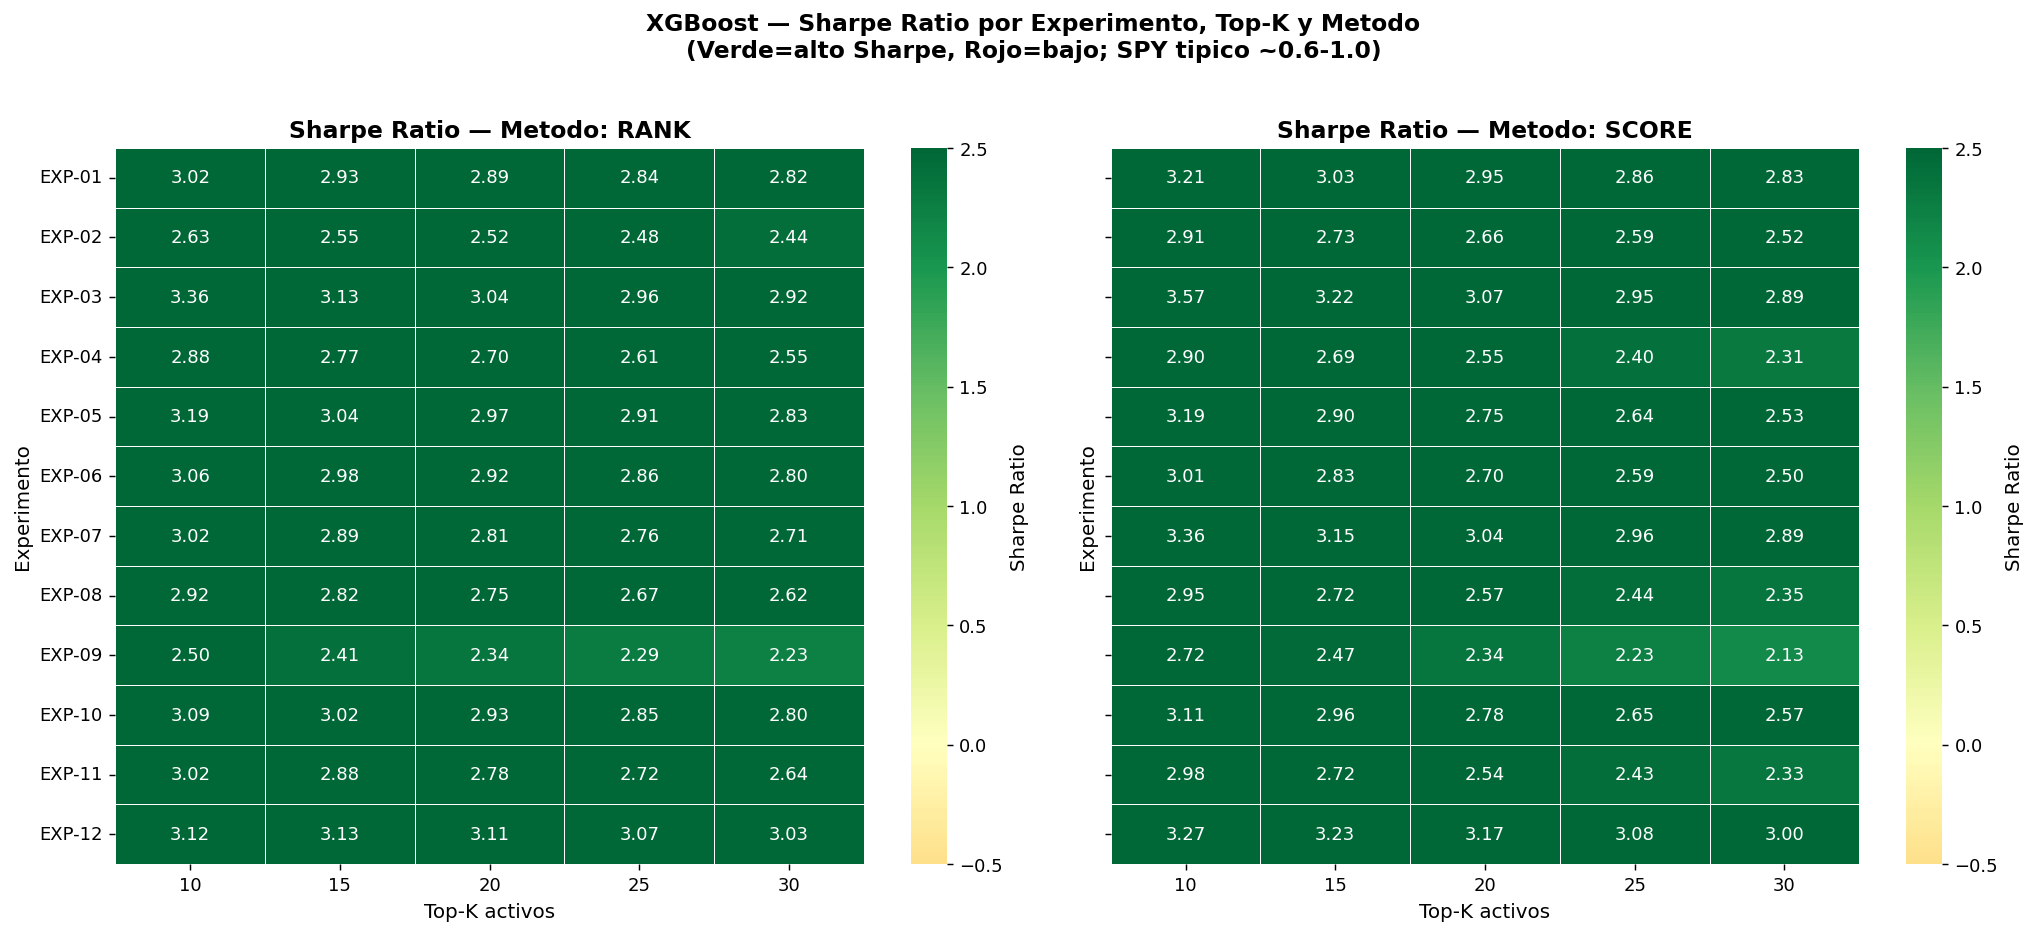

In [9]:
# Heatmap Sharpe Ratio
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, scheme in zip(axes, SCHEMES):
    sub   = results_df[results_df['scheme'] == scheme]
    pivot = sub.pivot_table(index='exp_id', columns='top_k', values='sharpe', aggfunc='mean')
    pivot = pivot.reindex([e['id'] for e in EXPERIMENTS if e['id'] in pivot.index])
    sns.heatmap(pivot, ax=ax, cmap='RdYlGn', center=0, vmin=-0.5, vmax=2.5,
                annot=True, fmt='.2f', linewidths=0.4,
                cbar_kws={'label': 'Sharpe Ratio'})
    ax.set_title(f'Sharpe Ratio — Metodo: {scheme.upper()}', fontweight='bold')
    ax.set_xlabel('Top-K activos'); ax.set_ylabel('Experimento')

plt.suptitle('XGBoost — Sharpe Ratio por Experimento, Top-K y Metodo\n'
             '(Verde=alto Sharpe, Rojo=bajo; SPY tipico ~0.6-1.0)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/heatmap_sharpe_experimentos.png', dpi=140, bbox_inches='tight')
plt.show()


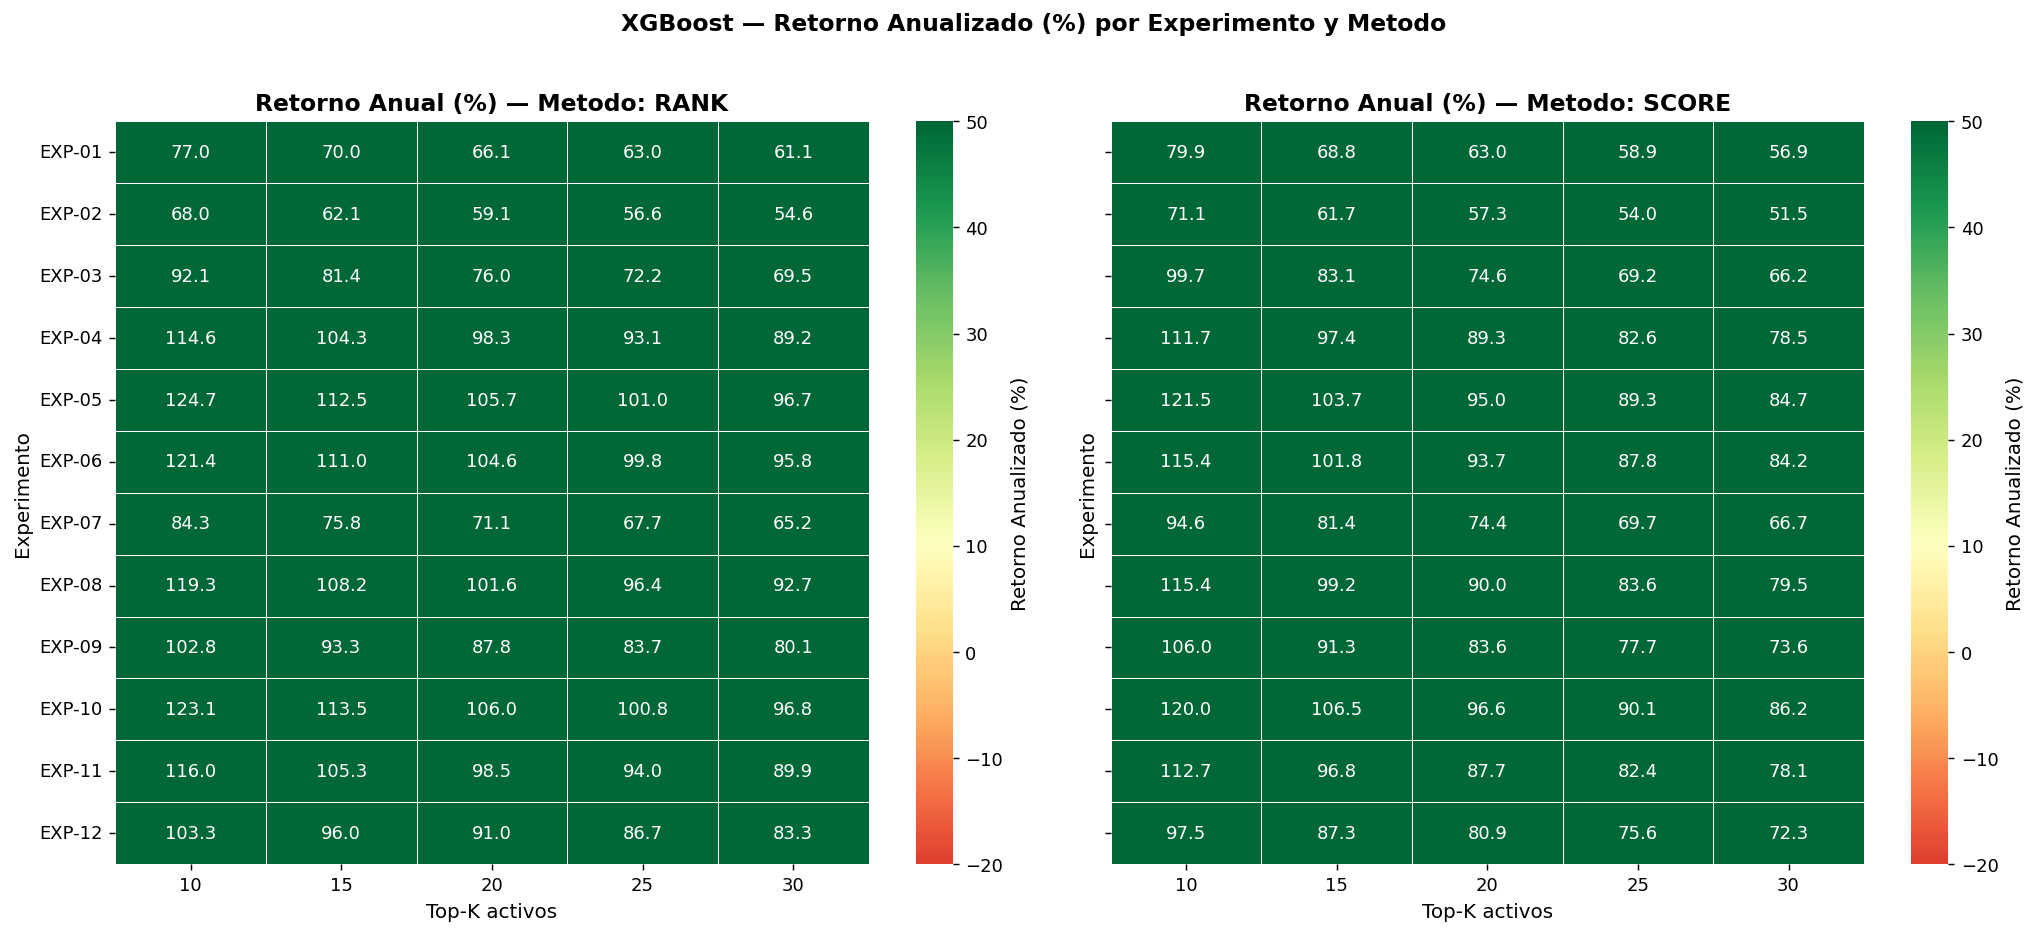

In [10]:
# Heatmap Retorno Anualizado
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, scheme in zip(axes, SCHEMES):
    sub   = results_df[results_df['scheme'] == scheme]
    pivot = sub.pivot_table(index='exp_id', columns='top_k', values='ret_annual', aggfunc='mean')
    pivot = pivot.reindex([e['id'] for e in EXPERIMENTS if e['id'] in pivot.index])
    sns.heatmap(pivot * 100, ax=ax, cmap='RdYlGn', center=10, vmin=-20, vmax=50,
                annot=True, fmt='.1f', linewidths=0.4,
                cbar_kws={'label': 'Retorno Anualizado (%)'})
    ax.set_title(f'Retorno Anual (%) — Metodo: {scheme.upper()}', fontweight='bold')
    ax.set_xlabel('Top-K activos'); ax.set_ylabel('Experimento')

plt.suptitle('XGBoost — Retorno Anualizado (%) por Experimento y Metodo',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/heatmap_retorno_experimentos.png', dpi=140, bbox_inches='tight')
plt.show()


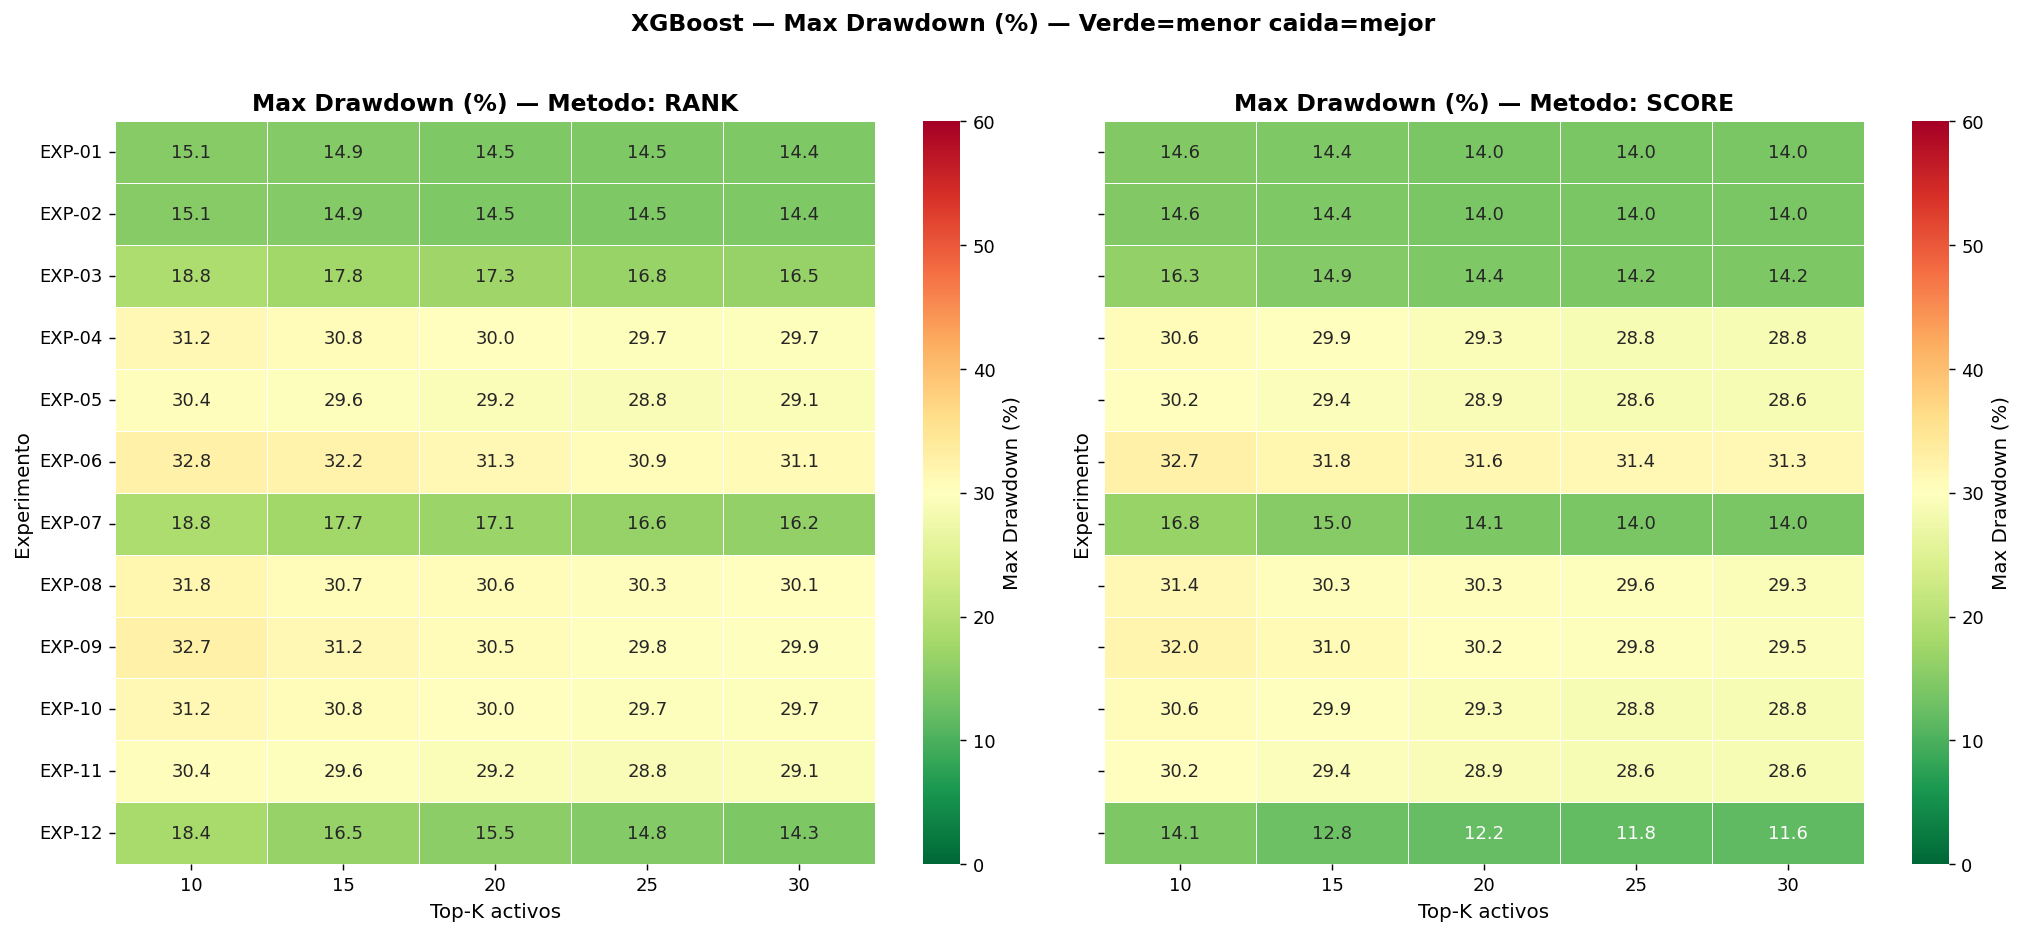

In [11]:
# Heatmap Max Drawdown
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, scheme in zip(axes, SCHEMES):
    sub   = results_df[results_df['scheme'] == scheme]
    pivot = sub.pivot_table(index='exp_id', columns='top_k', values='max_drawdown', aggfunc='mean')
    pivot = pivot.reindex([e['id'] for e in EXPERIMENTS if e['id'] in pivot.index])
    sns.heatmap(pivot.abs() * 100, ax=ax, cmap='RdYlGn_r', vmin=0, vmax=60,
                annot=True, fmt='.1f', linewidths=0.4,
                cbar_kws={'label': 'Max Drawdown (%)'})
    ax.set_title(f'Max Drawdown (%) — Metodo: {scheme.upper()}', fontweight='bold')
    ax.set_xlabel('Top-K activos'); ax.set_ylabel('Experimento')

plt.suptitle('XGBoost — Max Drawdown (%) — Verde=menor caida=mejor',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/heatmap_drawdown_experimentos.png', dpi=140, bbox_inches='tight')
plt.show()


---
## 7. Rank vs Score — Comparativa de Métodos de Pesos

COMPARATIVA RANK vs SCORE:
  sharpe                : rank=2.8255(±0.2360) | score=2.7938(±0.3074)
  ret_annual            : rank=0.9059(±0.1831) | score=0.8516(±0.1680)
  vol_annual            : rank=0.3022(±0.0604) | score=0.2880(±0.0601)
  max_drawdown          : rank=-0.2438(±0.0726) | score=-0.2334(±0.0797)
  calmar                : rank=3.8949(±0.7970) | score=3.9865(±1.2142)
  information_ratio     : rank=4.3257(±0.4690) | score=4.5176(±0.3710)
  ic_mean               : rank=0.5176(±0.0359) | score=0.5176(±0.0359)


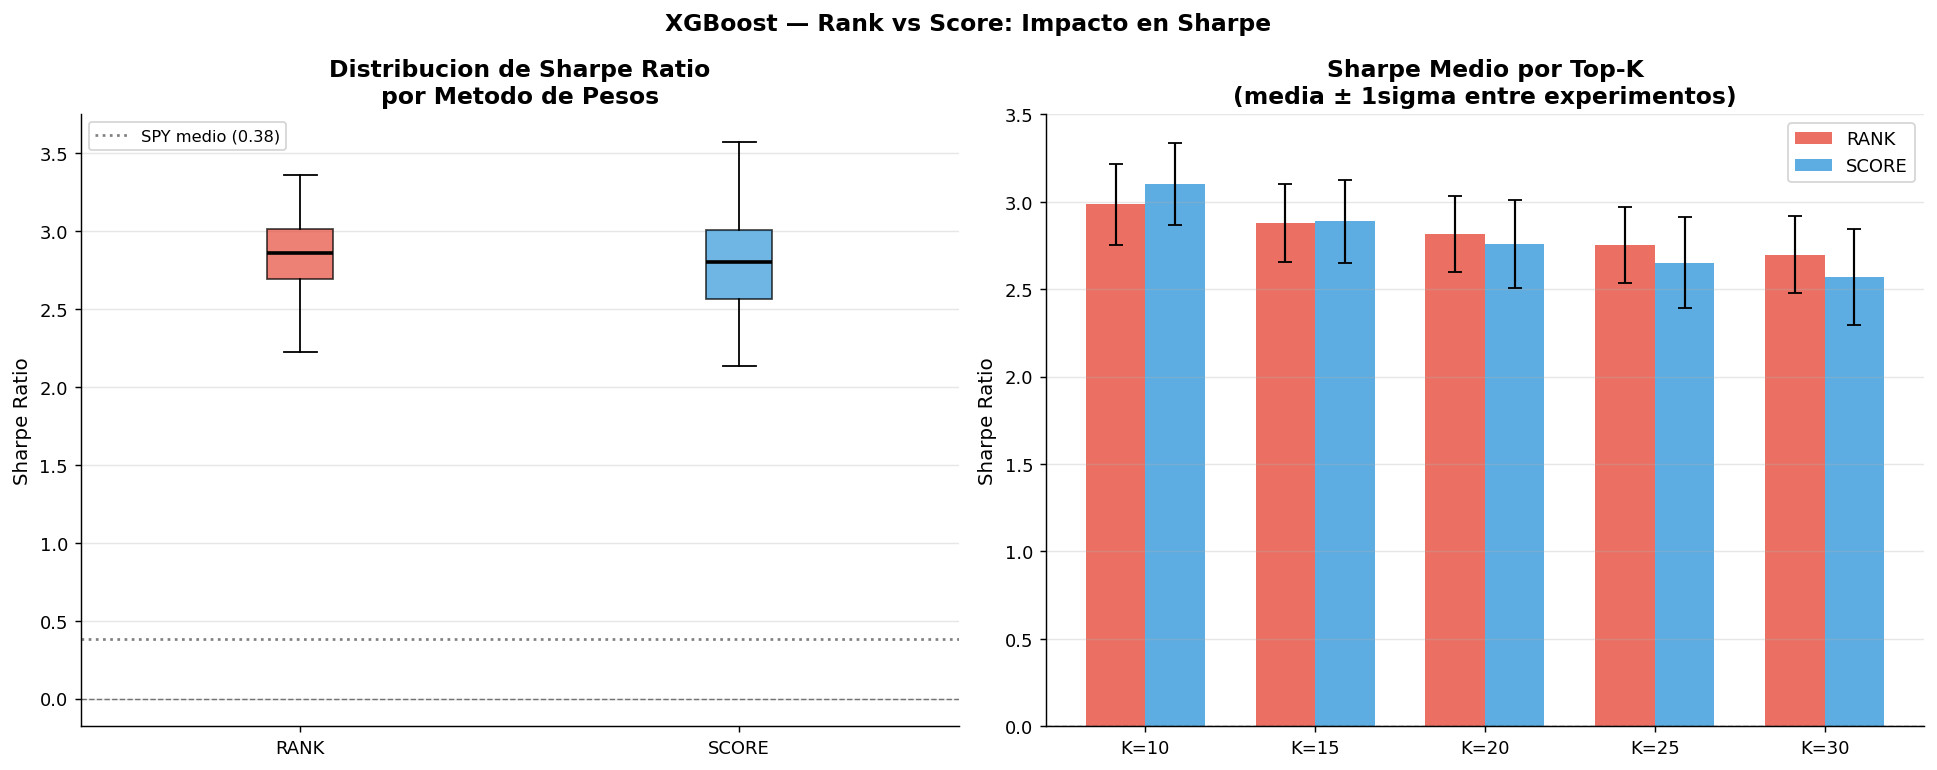

In [12]:
# Comparativa estadistica rank vs score
print('COMPARATIVA RANK vs SCORE:')
print('='*65)
for metric in ['sharpe','ret_annual','vol_annual','max_drawdown','calmar','information_ratio','ic_mean']:
    if metric not in results_df.columns: continue
    r_vals = results_df[results_df['scheme']=='rank'][metric].dropna()
    s_vals = results_df[results_df['scheme']=='score'][metric].dropna()
    print(f'  {metric:22s}: rank={r_vals.mean():.4f}(±{r_vals.std():.4f}) | '
          f'score={s_vals.mean():.4f}(±{s_vals.std():.4f})')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Boxplot Sharpe por metodo
ax = axes[0]
data_box = [results_df[results_df['scheme']==s]['sharpe'].dropna() for s in SCHEMES]
bp = ax.boxplot(data_box, labels=[s.upper() for s in SCHEMES], patch_artist=True,
                medianprops=dict(color='black', lw=2))
for patch, scheme in zip(bp['boxes'], SCHEMES):
    patch.set_facecolor(METHOD_COLORS.get(scheme, '#aaa'))
    patch.set_alpha(0.7)
ax.axhline(0, color='black', lw=0.8, linestyle='--', alpha=0.5)
spy_ref = results_df['sharpe_spy'].mean()
ax.axhline(spy_ref, color='gray', lw=1.5, linestyle=':', label=f'SPY medio ({spy_ref:.2f})')
ax.set_title('Distribucion de Sharpe Ratio\npor Metodo de Pesos', fontweight='bold')
ax.set_ylabel('Sharpe Ratio'); ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# Sharpe medio por Top-K desglosado por scheme
ax = axes[1]
x = np.arange(len(TOP_KS)); width = 0.35
for i, scheme in enumerate(SCHEMES):
    sub   = results_df[results_df['scheme'] == scheme]
    means = [sub[sub['top_k']==k]['sharpe'].mean() for k in TOP_KS]
    stds  = [sub[sub['top_k']==k]['sharpe'].std()  for k in TOP_KS]
    ax.bar(x + i*width, means, width, label=scheme.upper(),
           color=METHOD_COLORS.get(scheme, '#aaa'),
           alpha=0.8, yerr=stds, capsize=4, error_kw={'lw': 1.2})
ax.set_title('Sharpe Medio por Top-K\n(media ± 1sigma entre experimentos)', fontweight='bold')
ax.set_xticks(x + width/2)
ax.set_xticklabels([f'K={k}' for k in TOP_KS])
ax.set_ylabel('Sharpe Ratio')
ax.axhline(0, color='black', lw=0.8, linestyle='--', alpha=0.5)
ax.legend(fontsize=10); ax.grid(axis='y', alpha=0.3)

plt.suptitle('XGBoost — Rank vs Score: Impacto en Sharpe', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/rank_vs_score_sharpe.png', dpi=140, bbox_inches='tight')
plt.show()


---
## 8. Impacto de la Diversificación (Top-K ∈ {10, 15, 20, 25, 30})

IMPACTO DIVERSIFICACION (Top-K):
 top_k  sharpe_mean  sharpe_std  sharpe_median  ret_mean  vol_mean  mdd_mean  calmar_mean  pct_beat_spy  pct_beat_ew
    10       3.0424      0.2359         3.0208    1.0383    0.3255   -0.2504       4.3984           1.0          1.0
    15       2.8826      0.2238         2.8921    0.9218    0.3031   -0.2415       4.0823           1.0          1.0
    20       2.7863      0.2309         2.7824    0.8549    0.2899   -0.2362       3.8940           1.0          1.0
    25       2.7025      0.2405         2.6952    0.8066    0.2812   -0.2328       3.7322           1.0          1.0
    30       2.6345      0.2514         2.6292    0.7723    0.2757   -0.2322       3.5966           1.0          1.0


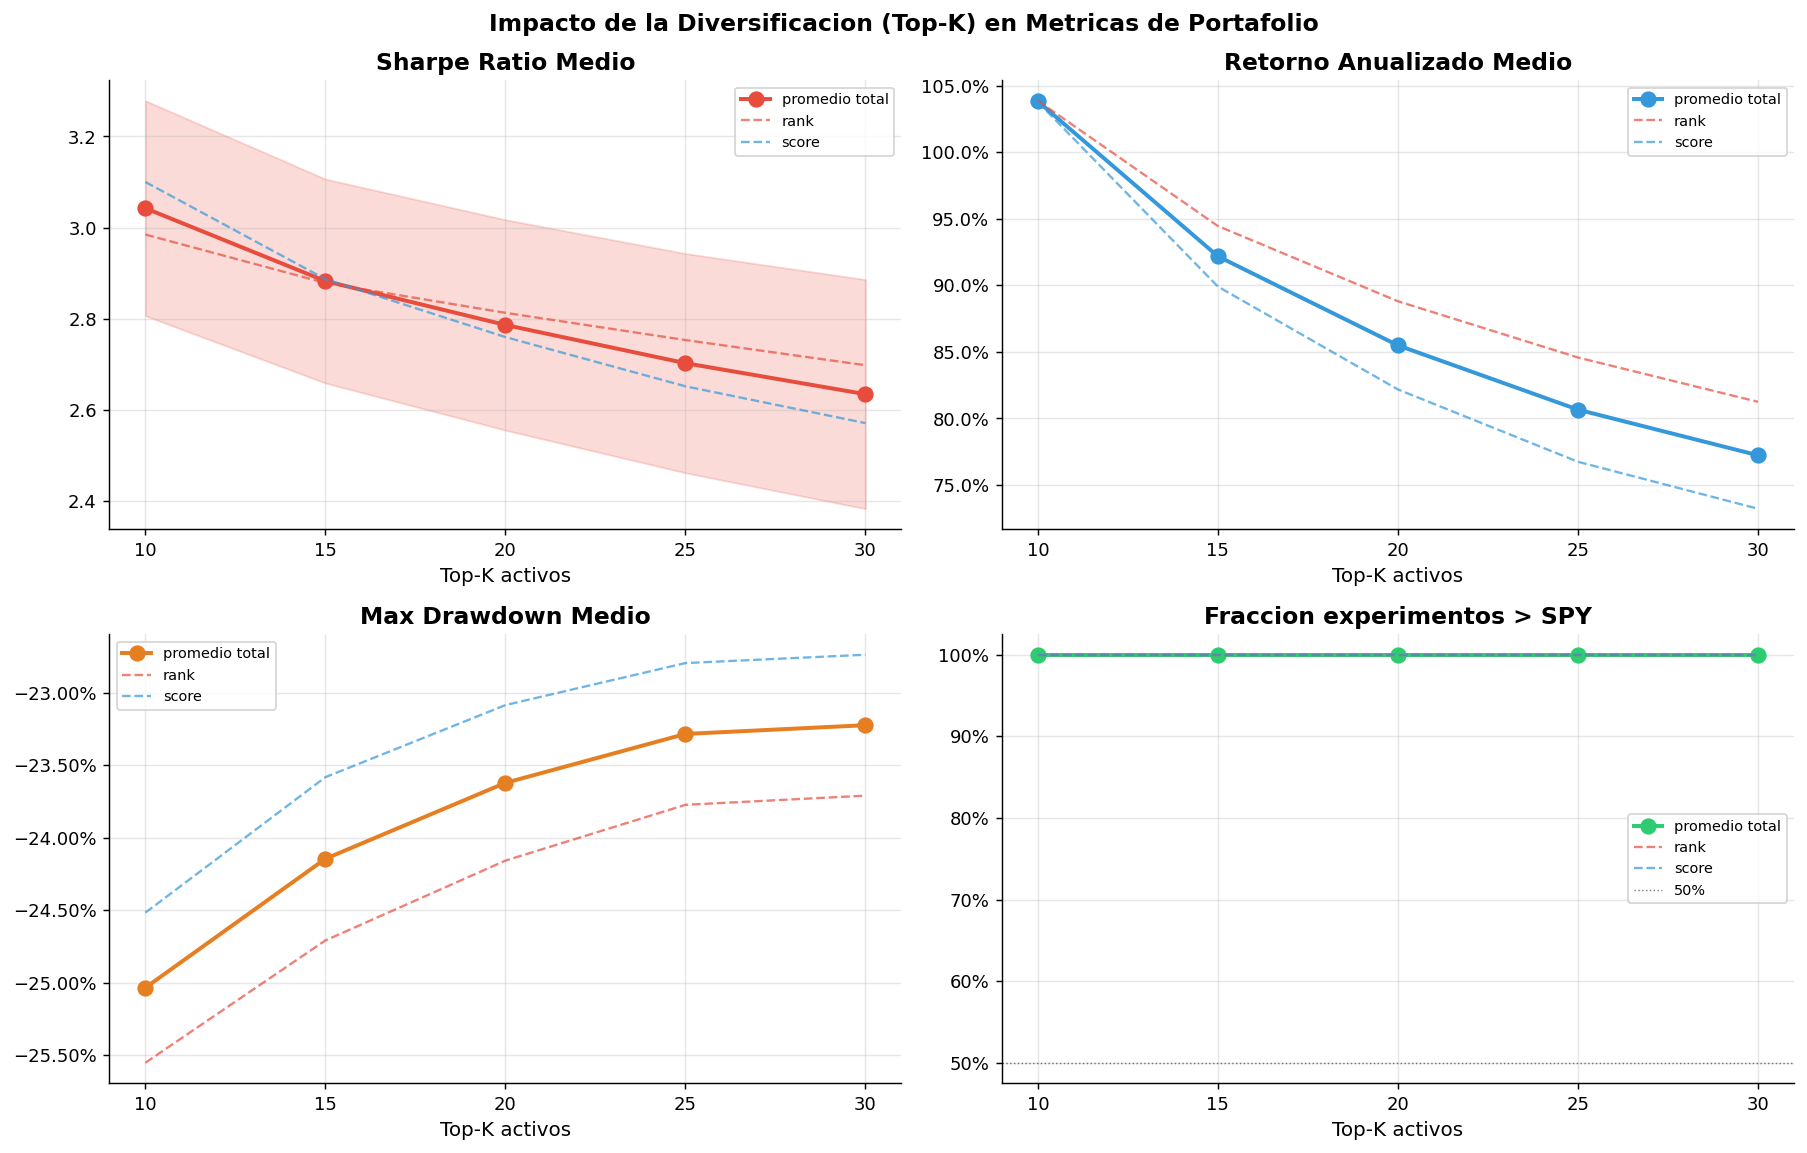

In [13]:
topk_summary = results_df.groupby('top_k').agg(
    sharpe_mean   = ('sharpe', 'mean'),
    sharpe_std    = ('sharpe', 'std'),
    sharpe_median = ('sharpe', 'median'),
    ret_mean      = ('ret_annual', 'mean'),
    vol_mean      = ('vol_annual', 'mean'),
    mdd_mean      = ('max_drawdown', 'mean'),
    calmar_mean   = ('calmar', 'mean'),
    pct_beat_spy  = ('beats_spy_sharpe', 'mean'),
    pct_beat_ew   = ('beats_ew_sharpe', 'mean'),
).reset_index()

print('IMPACTO DIVERSIFICACION (Top-K):')
print(topk_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
metrics_plot = [
    ('sharpe_mean', 'sharpe_std', 'sharpe', 'Sharpe Ratio Medio',         '#E74C3C'),
    ('ret_mean',    None,         'ret_annual', 'Retorno Anualizado Medio',   '#3498DB'),
    ('mdd_mean',    None,         'max_drawdown', 'Max Drawdown Medio',         '#E67E22'),
    ('pct_beat_spy',None,         'beats_spy_sharpe', 'Fraccion experimentos > SPY','#2ECC71'),
]

for ax, (metric, err_col, orig_col, title, color) in zip(axes.flat, metrics_plot):
    x = topk_summary['top_k'].values
    y = topk_summary[metric].values
    ax.plot(x, y, 'o-', color=color, lw=2.2, markersize=8, label='promedio total')
    if err_col and err_col in topk_summary.columns:
        err = topk_summary[err_col].values
        ax.fill_between(x, y - err, y + err, alpha=0.2, color=color)
    for scheme in SCHEMES:
        sub = results_df[results_df['scheme']==scheme].groupby('top_k')[orig_col].mean()
        ax.plot(sub.index, sub.values, '--', lw=1.3, alpha=0.7,
                color=METHOD_COLORS.get(scheme, '#aaa'), label=scheme)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Top-K activos'); ax.set_xticks(TOP_KS)
    ax.grid(True, alpha=0.3)
    if 'Fraccion' in title:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        ax.axhline(0.5, color='black', lw=0.8, linestyle=':', alpha=0.5, label='50%')
    elif 'Retorno' in title or 'Drawdown' in title:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(fontsize=8)


plt.suptitle('Impacto de la Diversificacion (Top-K) en Metricas de Portafolio',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/impacto_topk.png', dpi=140, bbox_inches='tight')
plt.show()


---
## 9. Empresas más Seleccionadas en Todos los Experimentos

In [14]:
# Frecuencia de seleccion global
freq_all = (
    selection_df.groupby('Ticker').size()
    .rename('total_selecciones')
    .sort_values(ascending=False)
)
total_slots  = len(selection_df)
freq_all_pct = (freq_all / total_slots * 100).rename('pct')
freq_df      = pd.DataFrame({'total': freq_all, 'pct': freq_all_pct})
freq_df['sector'] = freq_df.index.map(lambda t: SECTOR_LOOKUP.get(t, 'Unknown'))
freq_df = freq_df.sort_values('total', ascending=False)

print('TOP 20 activos mas seleccionados (todos los experimentos × schemes × Top-K):')
print(freq_df.head(20).round(2).to_string())


TOP 20 activos mas seleccionados (todos los experimentos × schemes × Top-K):
        total   pct                  sector
Ticker                                     
NOW      1956  3.40  Information Technology
NVDA     1946  3.38  Information Technology
AMD      1918  3.33  Information Technology
TSLA     1874  3.25  Consumer Discretionary
MSFT     1788  3.10  Information Technology
AMZN     1748  3.03  Consumer Discretionary
QCOM     1734  3.01  Information Technology
ISRG     1700  2.95             Health Care
TJX      1690  2.93  Consumer Discretionary
LOW      1620  2.81  Consumer Discretionary
AVGO     1586  2.75  Information Technology
RCL      1544  2.68  Consumer Discretionary
AAPL     1530  2.66  Information Technology
MDT      1520  2.64             Health Care
TXN      1516  2.63  Information Technology
ABBV     1508  2.62             Health Care
PM       1442  2.50        Consumer Staples
CSCO     1440  2.50  Information Technology
BKNG     1424  2.47  Consumer Discretionary

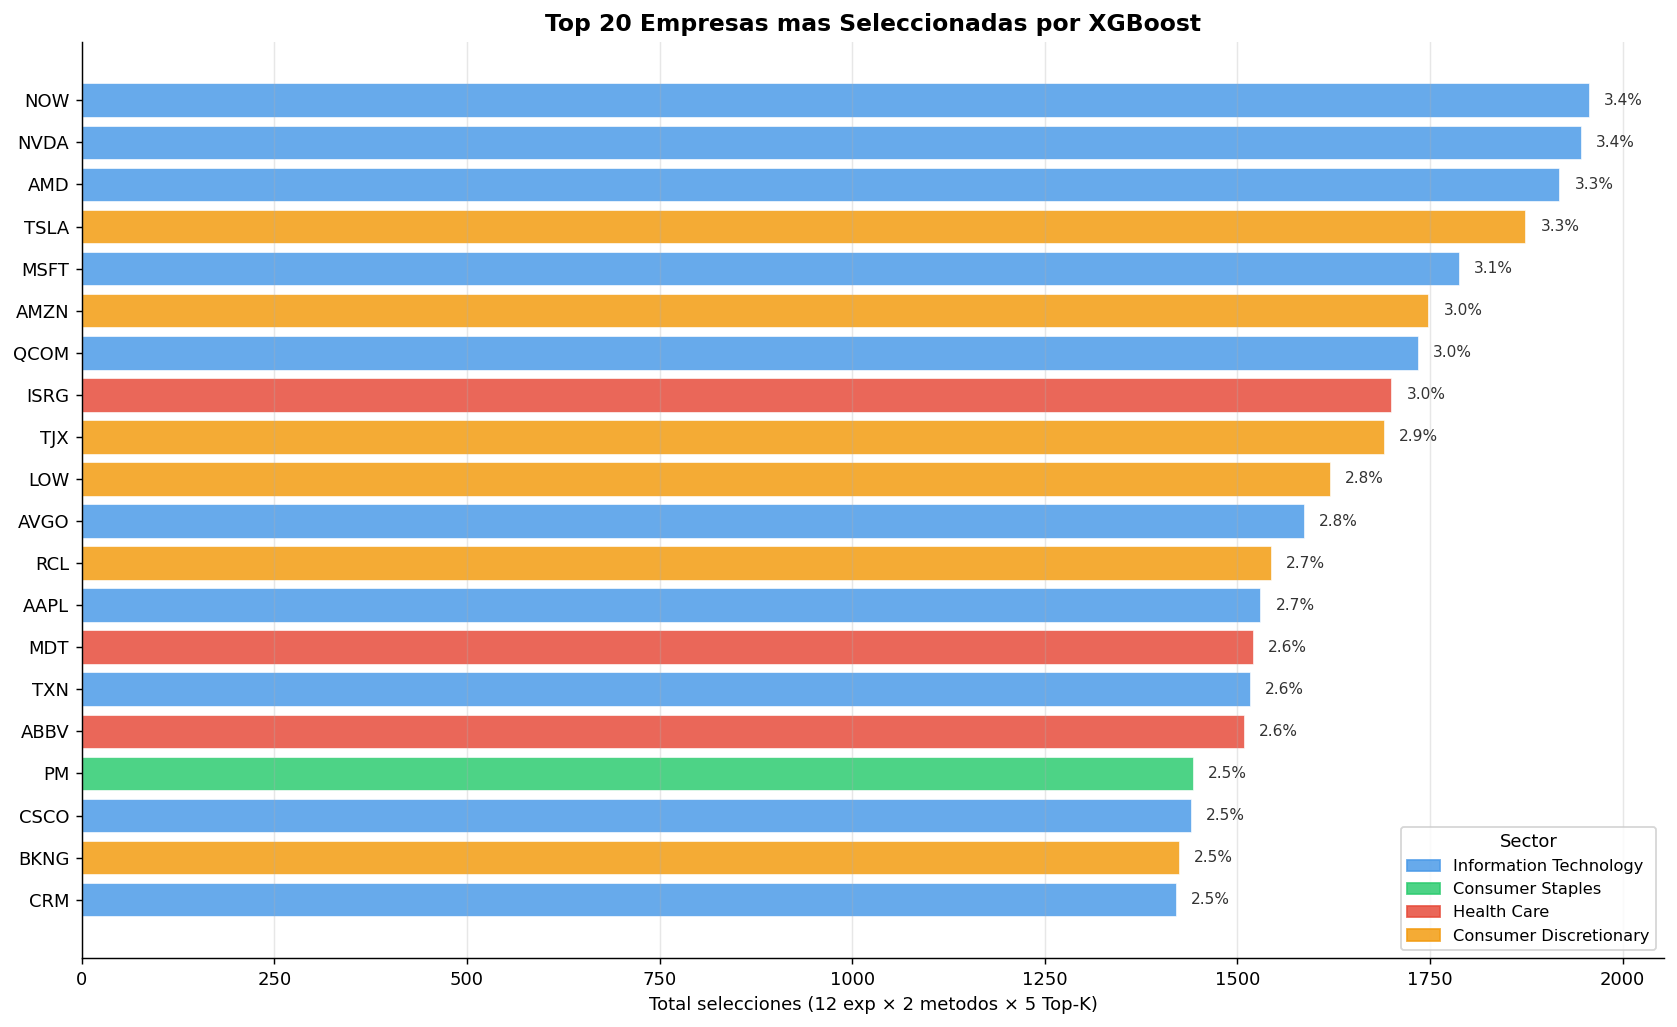

In [15]:
top_n      = min(20, len(freq_df))
freq_top   = freq_df.head(top_n).copy()
colors_bar = [SECTOR_COLORS.get(s, '#aaa') for s in freq_top['sector']]

fig, ax = plt.subplots(figsize=(13, 8))
bars = ax.barh(range(top_n), freq_top['total'].values,
               color=colors_bar, alpha=0.85, edgecolor='white', linewidth=0.4)
ax.set_yticks(range(top_n))
ax.set_yticklabels(freq_top.index, fontsize=10)
ax.set_xlabel(
    f'Total selecciones ({len(EXPERIMENTS)} exp × {len(SCHEMES)} metodos × {len(TOP_KS)} Top-K)',
    fontsize=10)
ax.set_title(f'Top {top_n} Empresas mas Seleccionadas por XGBoost', fontweight='bold')
for i, (bar, row) in enumerate(zip(bars, freq_top.itertuples())):
    ax.text(bar.get_width() + freq_top['total'].max() * 0.01, i,
            f'{row.pct:.1f}%', va='center', fontsize=8.5, color='#333')
legend_patches = [
    mpatches.Patch(color=c, label=s, alpha=0.85)
    for s, c in SECTOR_COLORS.items() if s != 'Unknown'
]
ax.legend(handles=legend_patches, loc='lower right', fontsize=9, title='Sector')
ax.grid(axis='x', alpha=0.3); ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/frecuencia_seleccion_global.png', dpi=140, bbox_inches='tight')
plt.show()


Total combinaciones: 120

Top 20 empresas mas ESTABLES (mayor presencia en % de combinaciones):
        n_combos  pct_combos                  sector
Ticker                                              
AAPL         120       100.0  Information Technology
BKNG         120       100.0  Consumer Discretionary
LOW          120       100.0  Consumer Discretionary
ABT          120       100.0             Health Care
AMD          120       100.0  Information Technology
AMGN         120       100.0             Health Care
AMZN         120       100.0  Consumer Discretionary
AVGO         120       100.0  Information Technology
WMT          120       100.0        Consumer Staples
MCD          120       100.0  Consumer Discretionary
CRM          120       100.0  Information Technology
CSCO         120       100.0  Information Technology
GIS          120       100.0        Consumer Staples
HD           120       100.0  Consumer Discretionary
HRL          120       100.0        Consumer Staples
ISR

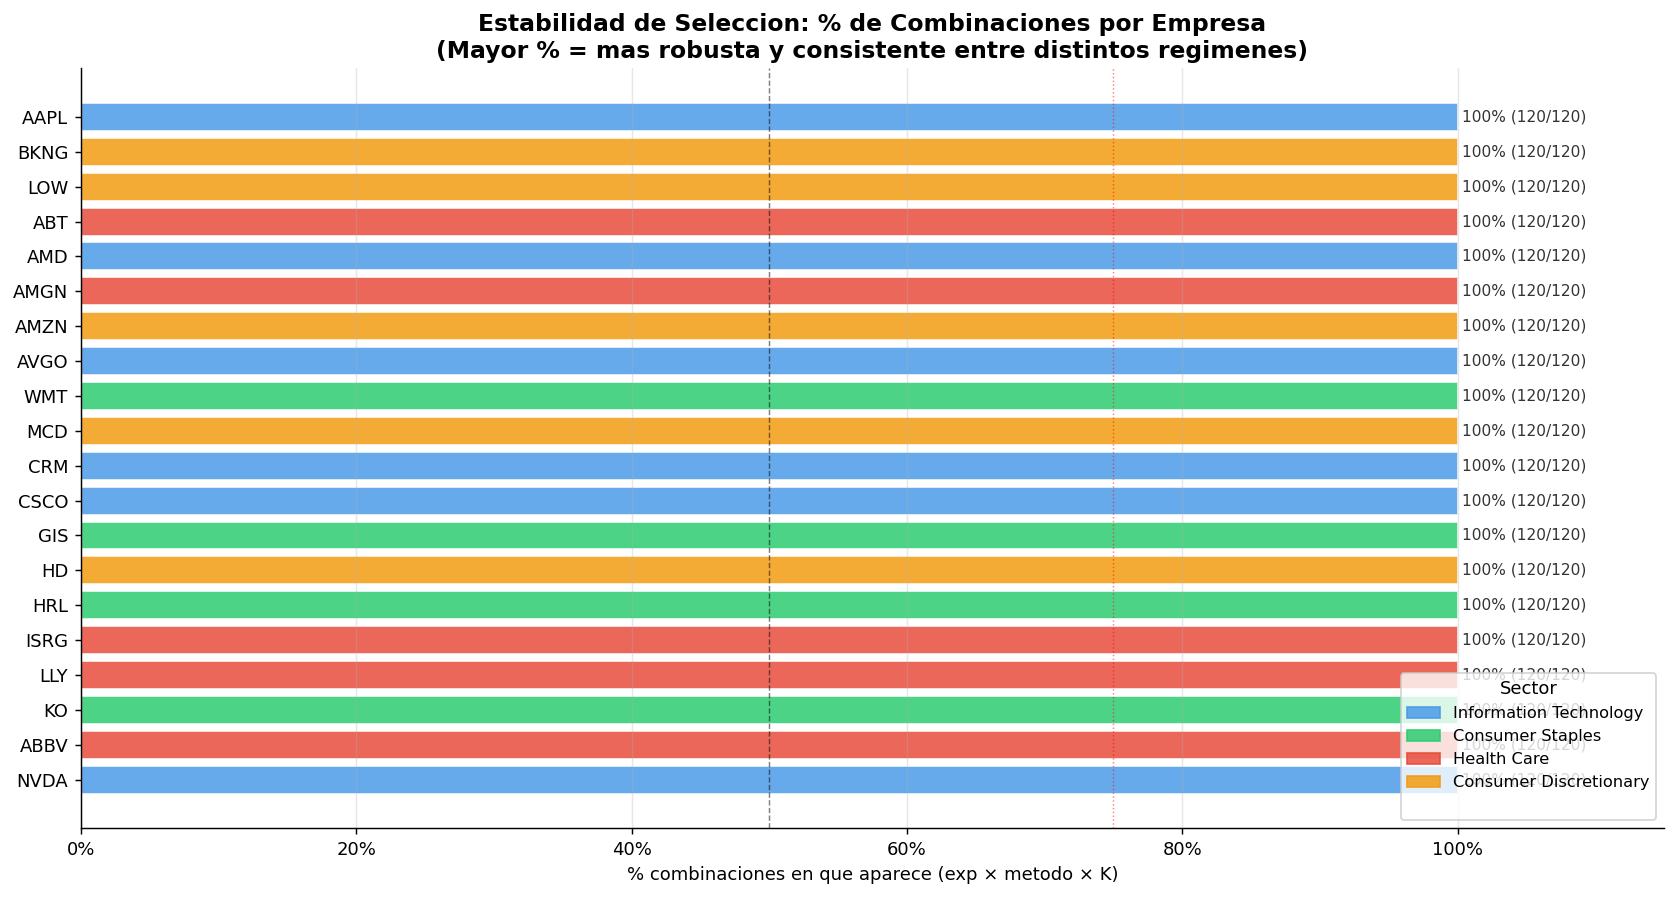

In [16]:
# Estabilidad: % combinaciones en que aparece cada empresa
n_combinations = results_df['combo_id'].nunique()

ticker_combo_count = (
    selection_df
    .assign(combo_id=(selection_df['exp_id'] + '_' +
                      selection_df['scheme'] + '_K' +
                      selection_df['top_k'].astype(str)))
    .groupby('Ticker')['combo_id'].nunique()
    .rename('n_combos')
    .sort_values(ascending=False)
)
ticker_pct = (ticker_combo_count / n_combinations * 100).rename('pct_combos')
stability_df = pd.DataFrame({'n_combos': ticker_combo_count, 'pct_combos': ticker_pct})
stability_df['sector'] = stability_df.index.map(lambda t: SECTOR_LOOKUP.get(t, 'Unknown'))
stability_df = stability_df.sort_values('pct_combos', ascending=False)

print(f'Total combinaciones: {n_combinations}')
print('\nTop 20 empresas mas ESTABLES (mayor presencia en % de combinaciones):')
print(stability_df.head(20).round(2).to_string())

# Grafico de estabilidad
top_stable  = stability_df.head(20)
colors_st   = [SECTOR_COLORS.get(s, '#aaa') for s in top_stable['sector']]

fig, ax = plt.subplots(figsize=(13, 7))
bars = ax.barh(range(len(top_stable)), top_stable['pct_combos'].values,
               color=colors_st, alpha=0.85, edgecolor='white')
ax.set_yticks(range(len(top_stable)))
ax.set_yticklabels(top_stable.index, fontsize=10)
ax.set_xlabel('% combinaciones en que aparece (exp × metodo × K)', fontsize=10)
ax.set_title('Estabilidad de Seleccion: % de Combinaciones por Empresa\n'
             '(Mayor % = mas robusta y consistente entre distintos regimenes)',
             fontweight='bold')
ax.axvline(50, color='black', lw=0.8, linestyle='--', alpha=0.5, label='50%')
ax.axvline(75, color='red',   lw=0.8, linestyle=':',  alpha=0.5, label='75%')
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%.0f%%'))
for i, (bar, row) in enumerate(zip(bars, top_stable.itertuples())):
    ax.text(bar.get_width() + 0.3, i,
            f'{row.pct_combos:.0f}% ({row.n_combos}/{n_combinations})',
            va='center', fontsize=8.5, color='#333')
legend_patches = [
    mpatches.Patch(color=c, label=s, alpha=0.85)
    for s, c in SECTOR_COLORS.items() if s != 'Unknown'
]
ax.legend(handles=legend_patches + [
    mpatches.Patch(color='none', label=''),
], loc='lower right', fontsize=9, title='Sector')
ax.grid(axis='x', alpha=0.3); ax.invert_yaxis()
ax.set_xlim(0, top_stable['pct_combos'].max() * 1.15)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/estabilidad_seleccion.png', dpi=140, bbox_inches='tight')
plt.show()


---
## 10. Comparación vs XGBoost Baseline del Notebook 06

El **XGBoost-06** usó una única ventana de entrenamiento (2015-2019 completo) y
se evaluó con OOS 2020+. Aquí comparamos sus métricas con nuestros 12 experimentos.


In [17]:
pred_nb06_path = f'{ML_DIR}/predictions_xgb.parquet'
try:
    pred_nb06 = pd.read_parquet(pred_nb06_path)
    print(f'Predicciones NB-06 cargadas: {pred_nb06.shape}')
    print(f'Rango: {pred_nb06["Date"].min().date()} -> {pred_nb06["Date"].max().date()}')
    NB06_AVAILABLE = True
except FileNotFoundError:
    print('No se encontraron predicciones del NB-06.')
    print('Ejecutar 06_supervised_learning.ipynb primero (o re-entrenando in-situ)...')
    NB06_AVAILABLE = False

if not NB06_AVAILABLE:
    print('Re-entrenando XGBoost baseline (2015-2019 -> OOS 2020-2022)...')
    xgb_baseline = make_xgb_model()
    pred_nb06 = sliding_window_predict(
        ml_df_clean, FEATURE_FINAL, xgb_baseline,
        train_start='2015-01-02', train_end='2019-12-31',
        oos_start='2020-01-01',   oos_end='2022-12-31',
    )
    print(f'Baseline: {len(pred_nb06)} filas | {pred_nb06["Date"].nunique()} meses')

baseline_results = []
spy_ref_oos = log_ret[
    (log_ret.index >= '2020-01-01') & (log_ret.index <= '2022-12-31')
][BENCHMARK]

if len(pred_nb06) > 0:
    for scheme in SCHEMES:
        for top_k in TOP_KS:
            w_b   = predictions_to_weights(pred_nb06, top_k=top_k, scheme=scheme)
            ret_b = backtest_portfolio(w_b, log_ret)
            if len(ret_b) < 10: continue
            m_b = portfolio_metrics(ret_b, spy_ref_oos)
            if not m_b: continue
            baseline_results.append({
                'scheme': scheme, 'top_k': top_k,
                'sharpe': m_b.get('sharpe', np.nan),
                'ret_annual': m_b.get('ret_annual', np.nan),
                'vol_annual': m_b.get('vol_annual', np.nan),
                'max_drawdown': m_b.get('max_drawdown', np.nan),
                'calmar': m_b.get('calmar', np.nan),
            })

baseline_df = pd.DataFrame(baseline_results)
print(f'\nBaseline evaluado en {len(baseline_df)} combinaciones scheme × top_k')
if len(baseline_df) > 0:
    print(baseline_df.groupby(['scheme','top_k']).agg(
        sharpe=('sharpe','mean'), ret_annual=('ret_annual','mean')
    ).round(4).to_string())


Predicciones NB-06 cargadas: (1760, 5)
Rango: 2020-01-31 -> 2025-01-31



Baseline evaluado en 10 combinaciones scheme × top_k
              sharpe  ret_annual
scheme top_k                    
rank   10     1.9029      0.6351
       15     1.8742      0.5905
       20     1.8782      0.5673
       25     1.8406      0.5401
       30     1.8047      0.5188
score  10     1.8564      0.5697
       15     1.8046      0.5193
       20     1.8151      0.4957
       25     1.7355      0.4603
       30     1.6853      0.4400


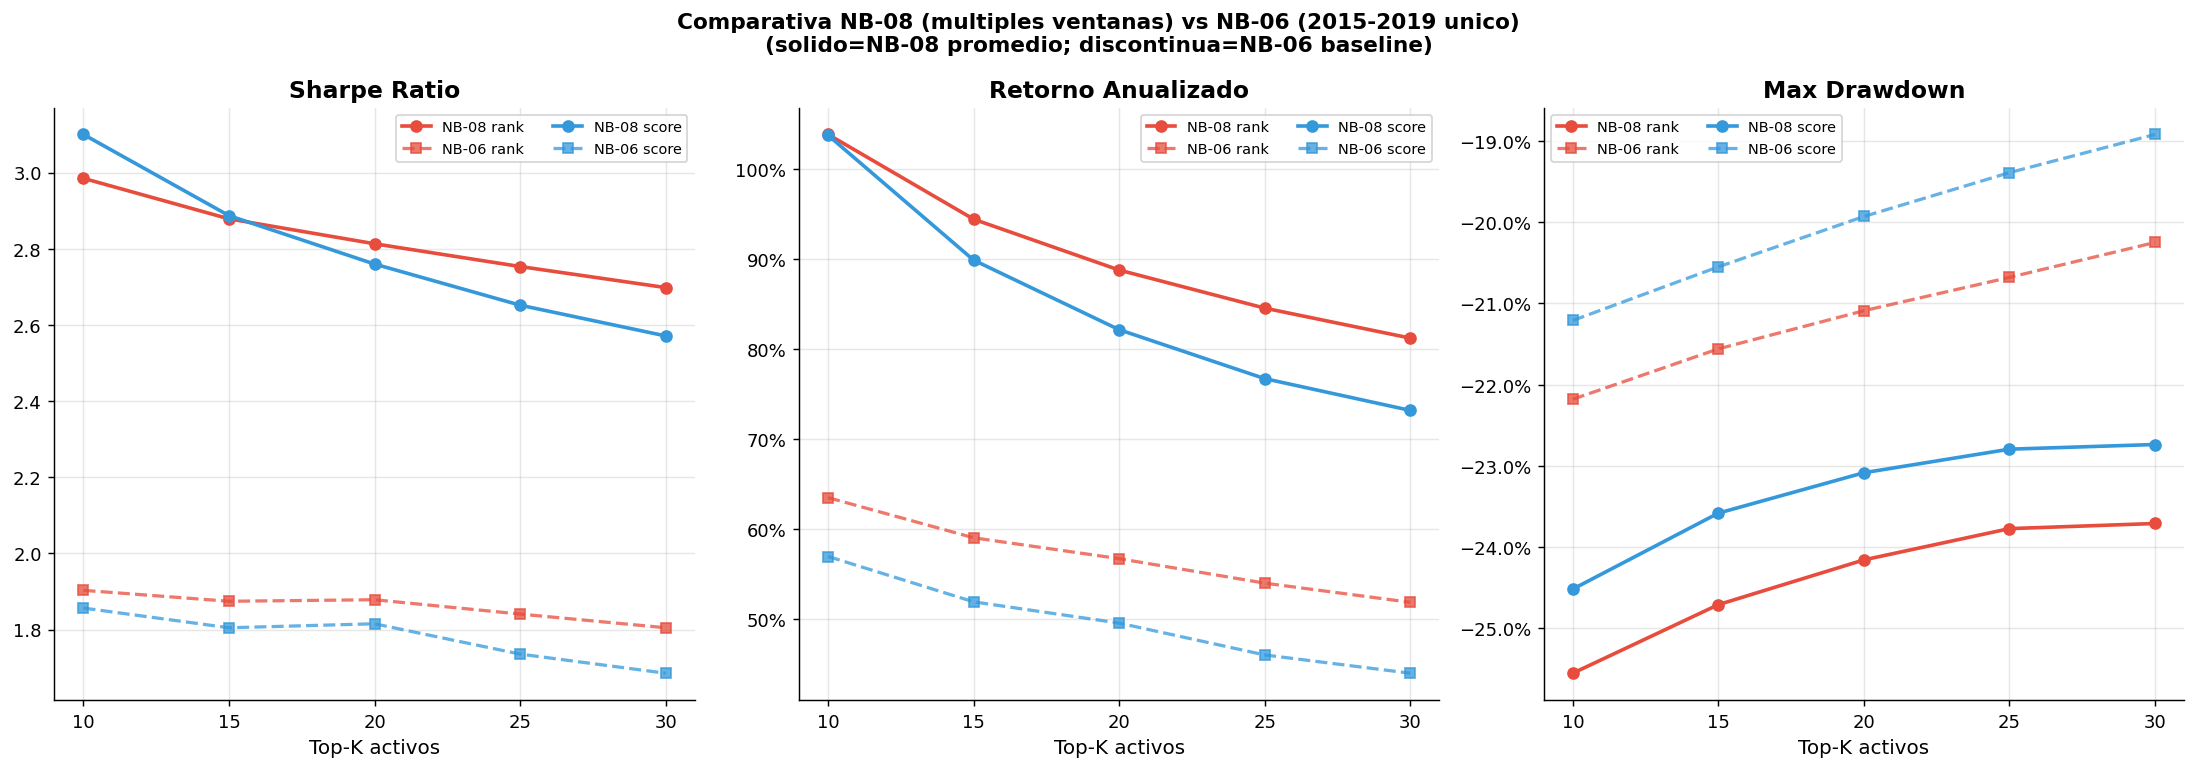

In [18]:
# Comparativa visual NB-06 vs NB-08
if len(baseline_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(17, 6))
    metrics_cmp = ['sharpe', 'ret_annual', 'max_drawdown']
    titles_cmp  = ['Sharpe Ratio', 'Retorno Anualizado', 'Max Drawdown']

    for ax, metric, title in zip(axes, metrics_cmp, titles_cmp):
        for scheme in SCHEMES:
            # NB-08 promedio
            sub08  = results_df[results_df['scheme']==scheme]
            vals08 = [sub08[sub08['top_k']==k][metric].mean() for k in TOP_KS]
            ax.plot(TOP_KS, vals08, 'o-', lw=2,
                    color=METHOD_COLORS.get(scheme, '#aaa'), label=f'NB-08 {scheme}')
            # NB-06 baseline
            sub06 = baseline_df[baseline_df['scheme']==scheme]
            if len(sub06) > 0:
                vals06 = []
                for k in TOP_KS:
                    sub_k = sub06[sub06['top_k']==k]
                    vals06.append(sub_k[metric].mean() if len(sub_k) > 0 else np.nan)
                ax.plot(TOP_KS, vals06, 's--', lw=1.8, alpha=0.75,
                        color=METHOD_COLORS.get(scheme, '#aaa'), label=f'NB-06 {scheme}')
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Top-K activos'); ax.set_xticks(TOP_KS)
        ax.grid(True, alpha=0.3)
        if metric in ['ret_annual', 'max_drawdown']:
            ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        ax.legend(fontsize=8, ncol=2)

    plt.suptitle('Comparativa NB-08 (multiples ventanas) vs NB-06 (2015-2019 unico)\n'
                 '(solido=NB-08 promedio; discontinua=NB-06 baseline)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/comparativa_nb06_nb08.png', dpi=140, bbox_inches='tight')
    plt.show()
else:
    print('No hay baseline para comparar graficamente')


---
## 11. Tabla Maestra de Resultados

In [19]:
print('TOP 15 COMBINACIONES POR SHARPE RATIO')
print('='*80)
top15_cols = ['combo_id','oos_start','oos_end','scheme','top_k',
              'sharpe','ret_annual','vol_annual','max_drawdown',
              'calmar','ic_mean','beats_spy_sharpe','beats_ew_sharpe']
top15 = results_df[top15_cols].sort_values('sharpe', ascending=False).head(15)
print(top15.round(4).to_string(index=False))

print('\n' + '='*80)
print('BOTTOM 10 COMBINACIONES POR SHARPE RATIO (peores)')
print('='*80)
bot10 = results_df[top15_cols].sort_values('sharpe', ascending=True).head(10)
print(bot10.round(4).to_string(index=False))

print('\n' + '='*80)
print('RESUMEN ESTADISTICO — Scheme × Top-K')
print('='*80)
summary_table = results_df.groupby(['scheme', 'top_k']).agg(
    n_exp         = ('sharpe', 'count'),
    sharpe_mean   = ('sharpe', 'mean'),
    sharpe_std    = ('sharpe', 'std'),
    sharpe_median = ('sharpe', 'median'),
    sharpe_min    = ('sharpe', 'min'),
    sharpe_max    = ('sharpe', 'max'),
    ret_mean      = ('ret_annual', 'mean'),
    vol_mean      = ('vol_annual', 'mean'),
    mdd_mean      = ('max_drawdown', 'mean'),
    ic_mean       = ('ic_mean', 'mean'),
    pct_beat_spy  = ('beats_spy_sharpe', 'mean'),
    pct_beat_ew   = ('beats_ew_sharpe', 'mean'),
).round(4)
print(summary_table.to_string())
summary_table.to_csv(f'{OUT_DIR}/resumen_scheme_topk.csv')


TOP 15 COMBINACIONES POR SHARPE RATIO
        combo_id  oos_start    oos_end scheme  top_k  sharpe  ret_annual  vol_annual  max_drawdown  calmar  ic_mean  beats_spy_sharpe  beats_ew_sharpe
EXP-03_score_K10 2018-01-01 2019-12-31  score     10  3.5745      0.9971      0.2643       -0.1628  6.1261   0.5314              True             True
EXP-07_score_K10 2018-01-01 2019-12-31  score     10  3.3644      0.9457      0.2655       -0.1677  5.6384   0.5289              True             True
 EXP-03_rank_K10 2018-01-01 2019-12-31   rank     10  3.3585      0.9206      0.2585       -0.1878  4.9009   0.5314              True             True
EXP-12_score_K10 2020-01-01 2021-12-31  score     10  3.2693      0.9751      0.2822       -0.1413  6.8997   0.4469              True             True
EXP-12_score_K15 2020-01-01 2021-12-31  score     15  3.2266      0.8729      0.2543       -0.1276  6.8389   0.4469              True             True
EXP-03_score_K15 2018-01-01 2019-12-31  score     15  3.

---
## 12. Dashboard Visual Final

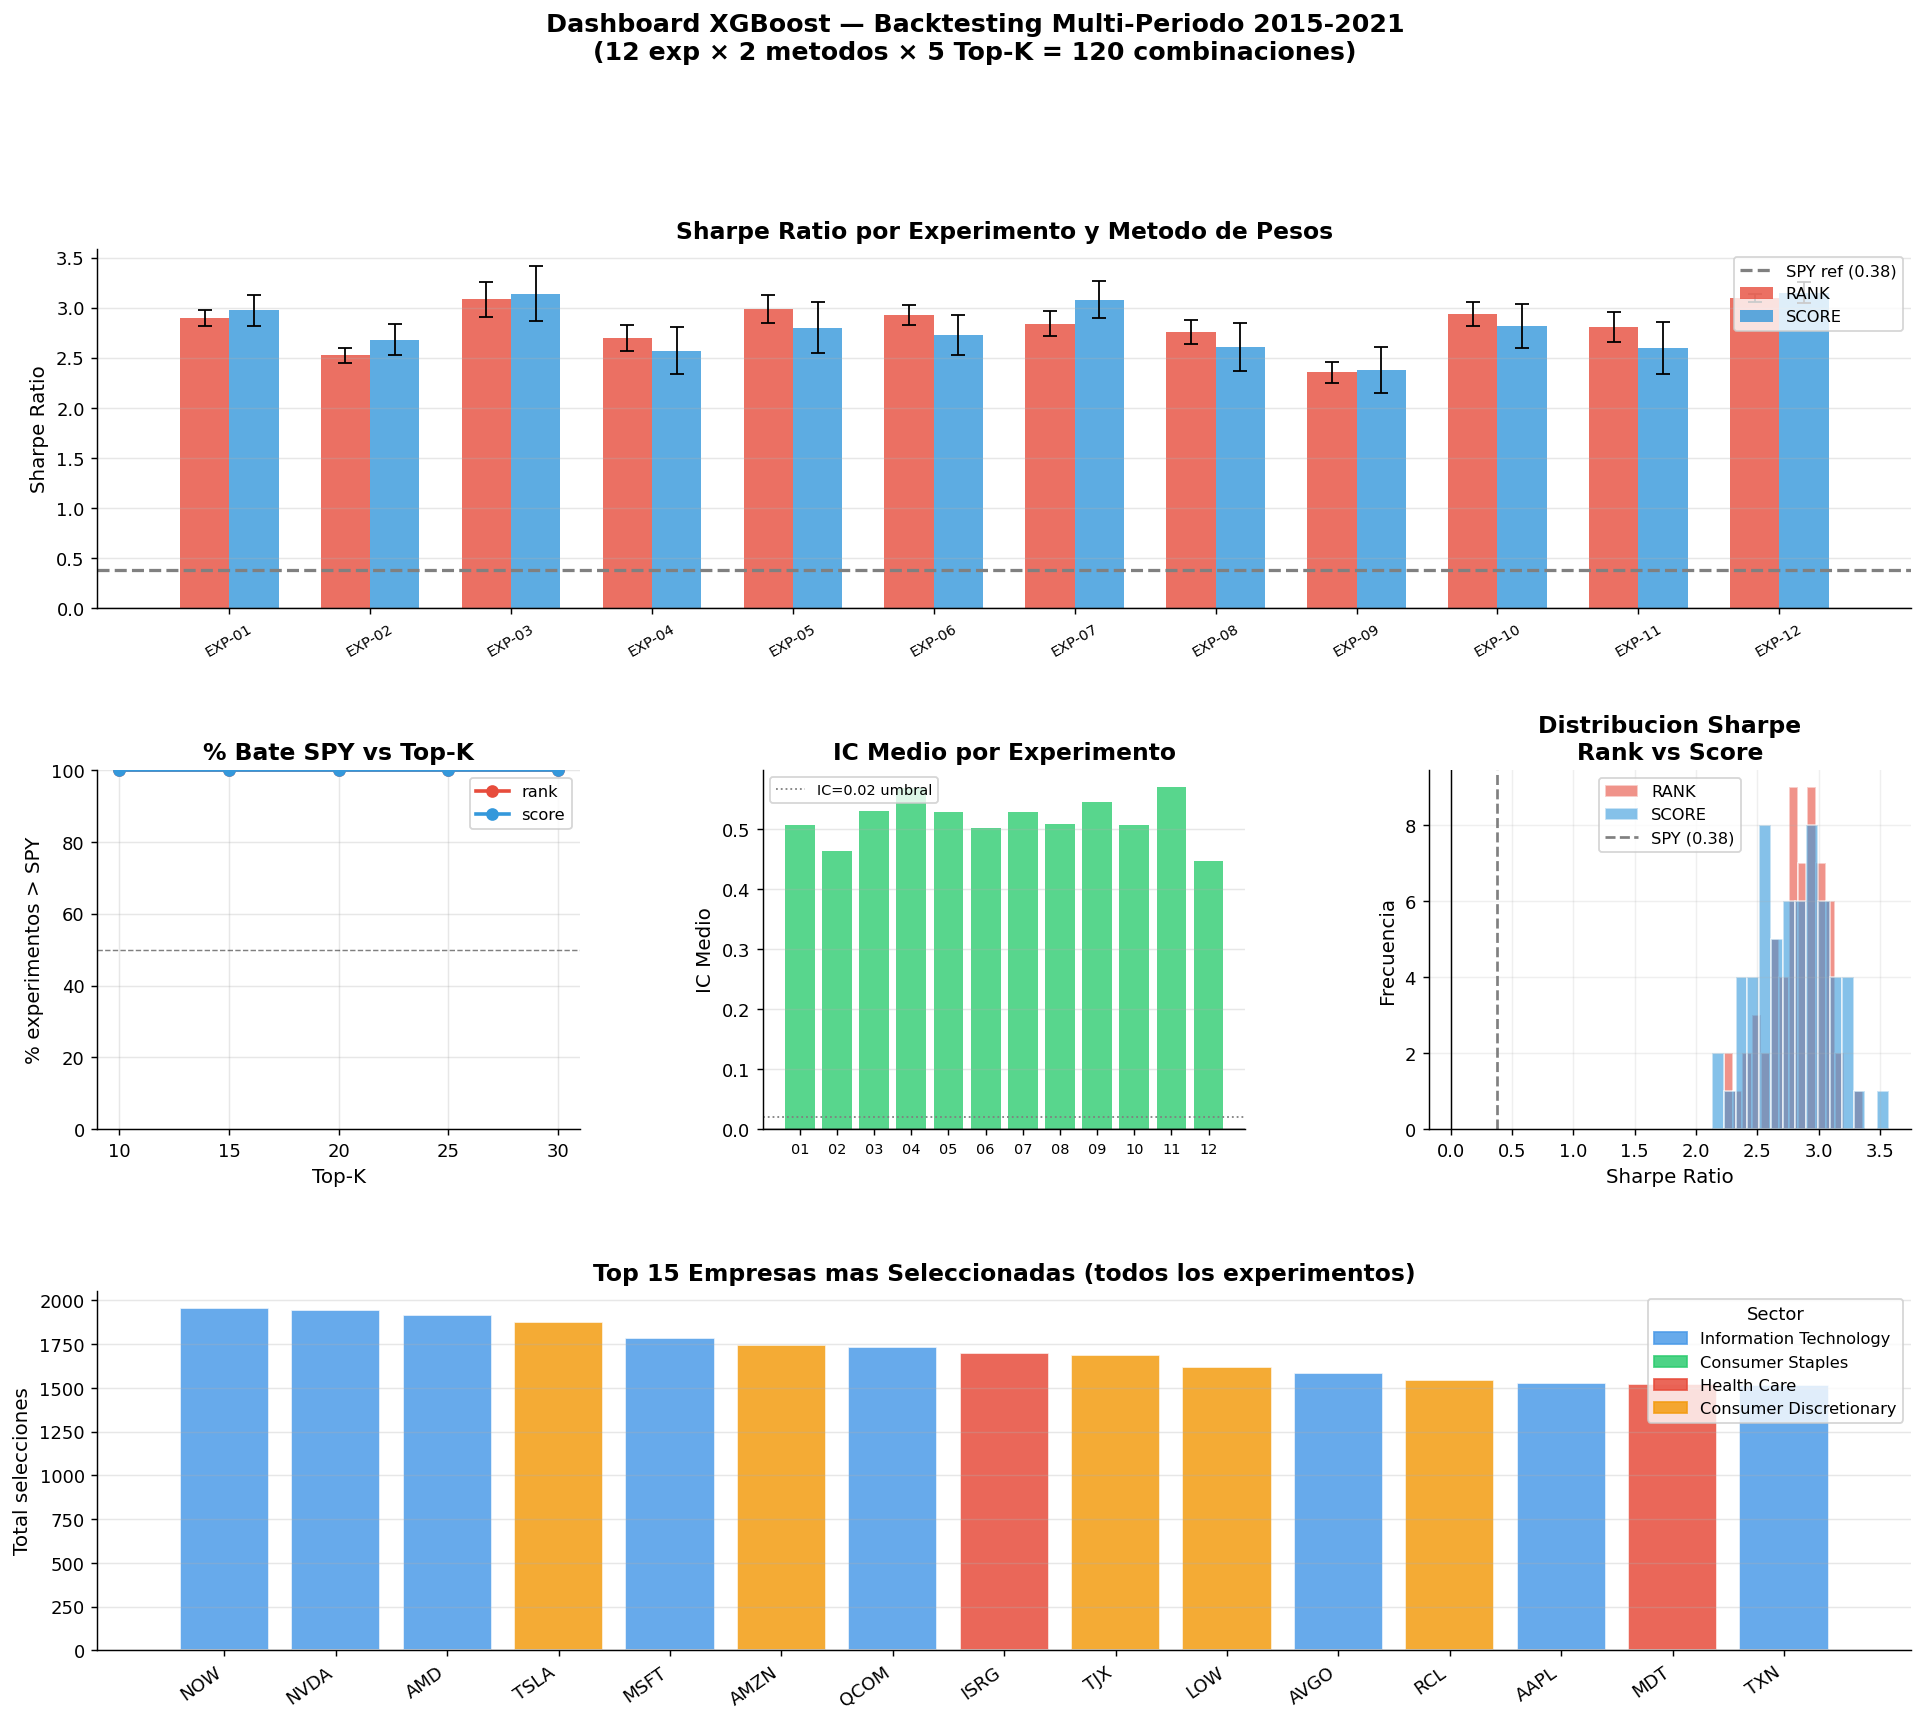

Dashboard guardado


In [20]:
exp_ids = [e['id'] for e in EXPERIMENTS if e['id'] in results_df['exp_id'].values]
fig = plt.figure(figsize=(18, 14))
gs  = GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.38)

# Panel 1: Sharpe por experimento y metodo
ax1 = fig.add_subplot(gs[0, :])
x_pos = np.arange(len(exp_ids))
w_g   = 0.35
spy_ref = results_df['sharpe_spy'].mean()
for i, scheme in enumerate(SCHEMES):
    means = [results_df[(results_df['exp_id']==eid) &
                        (results_df['scheme']==scheme)]['sharpe'].mean() for eid in exp_ids]
    stds  = [results_df[(results_df['exp_id']==eid) &
                        (results_df['scheme']==scheme)]['sharpe'].std()  for eid in exp_ids]
    ax1.bar(x_pos + i*w_g, means, w_g, label=scheme.upper(),
            color=METHOD_COLORS.get(scheme, '#aaa'),
            alpha=0.8, yerr=stds, capsize=4, error_kw={'lw': 1})
ax1.axhline(spy_ref, color='gray', lw=1.8, linestyle='--', label=f'SPY ref ({spy_ref:.2f})')
ax1.axhline(0, color='black', lw=0.8, alpha=0.3)
ax1.set_title('Sharpe Ratio por Experimento y Metodo de Pesos', fontweight='bold')
ax1.set_xticks(x_pos + w_g/2)
ax1.set_xticklabels(exp_ids, rotation=30, fontsize=8)
ax1.set_ylabel('Sharpe Ratio')
ax1.legend(fontsize=9, loc='upper right'); ax1.grid(axis='y', alpha=0.3)

# Panel 2: % bate SPY por Top-K
ax2 = fig.add_subplot(gs[1, 0])
for scheme in SCHEMES:
    sub = results_df[results_df['scheme']==scheme].groupby('top_k')['beats_spy_sharpe'].mean()
    ax2.plot(sub.index, sub.values * 100, 'o-', lw=2,
             color=METHOD_COLORS.get(scheme, '#aaa'), label=scheme)
ax2.axhline(50, color='black', lw=0.8, linestyle='--', alpha=0.5)
ax2.set_title('% Bate SPY vs Top-K', fontweight='bold')
ax2.set_xlabel('Top-K'); ax2.set_ylabel('% experimentos > SPY')
ax2.set_xticks(TOP_KS); ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3); ax2.set_ylim(0, 100)

# Panel 3: IC medio por experimento
ax3 = fig.add_subplot(gs[1, 1])
ic_by_exp = results_df.groupby('exp_id')['ic_mean'].mean().reindex(exp_ids)
colors_ic = ['#2ECC71' if v > 0 else '#E74C3C' for v in ic_by_exp]
ax3.bar(range(len(exp_ids)), ic_by_exp.values, color=colors_ic, alpha=0.8)
ax3.axhline(0, color='black', lw=0.8)
ax3.axhline(0.02, color='gray', lw=1, linestyle=':', label='IC=0.02 umbral')
ax3.set_title('IC Medio por Experimento', fontweight='bold')
ax3.set_xticks(range(len(exp_ids)))
ax3.set_xticklabels([e.replace('EXP-','') for e in exp_ids], fontsize=8)
ax3.set_ylabel('IC Medio'); ax3.legend(fontsize=8); ax3.grid(axis='y', alpha=0.3)

# Panel 4: Histograma Sharpe rank vs score
ax4 = fig.add_subplot(gs[1, 2])
for scheme in SCHEMES:
    vals = results_df[results_df['scheme']==scheme]['sharpe'].dropna()
    ax4.hist(vals, bins=15, alpha=0.6, label=scheme.upper(),
             color=METHOD_COLORS.get(scheme, '#aaa'), edgecolor='white')
ax4.axvline(spy_ref, color='gray', lw=1.5, linestyle='--', label=f'SPY ({spy_ref:.2f})')
ax4.axvline(0, color='black', lw=0.8)
ax4.set_title('Distribucion Sharpe\nRank vs Score', fontweight='bold')
ax4.set_xlabel('Sharpe Ratio'); ax4.set_ylabel('Frecuencia')
ax4.legend(fontsize=9); ax4.grid(True, alpha=0.2)

# Panel 5: Top 15 empresas mas seleccionadas
ax5 = fig.add_subplot(gs[2, :])
top15_emp  = freq_df.head(15)
colors_t15 = [SECTOR_COLORS.get(s, '#aaa') for s in top15_emp['sector']]
ax5.bar(range(len(top15_emp)), top15_emp['total'].values,
        color=colors_t15, alpha=0.85, edgecolor='white')
ax5.set_xticks(range(len(top15_emp)))
ax5.set_xticklabels(top15_emp.index, rotation=35, ha='right', fontsize=10)
ax5.set_title('Top 15 Empresas mas Seleccionadas (todos los experimentos)', fontweight='bold')
ax5.set_ylabel('Total selecciones')
legend_patches = [
    mpatches.Patch(color=c, label=s, alpha=0.85)
    for s, c in SECTOR_COLORS.items() if s != 'Unknown'
]
ax5.legend(handles=legend_patches, loc='upper right', fontsize=9, title='Sector')
ax5.grid(axis='y', alpha=0.3)

plt.suptitle(
    f'Dashboard XGBoost — Backtesting Multi-Periodo 2015-2021\n'
    f'({len(EXPERIMENTS)} exp × {len(SCHEMES)} metodos × {len(TOP_KS)} Top-K = {len(results_df)} combinaciones)',
    fontsize=14, fontweight='bold', y=1.01
)
plt.savefig(f'{OUT_DIR}/dashboard_resumen.png', dpi=140, bbox_inches='tight')
plt.show()
print('Dashboard guardado')


---
## 13. Persistencia de Resultados

In [21]:
results_df.to_csv(f'{OUT_DIR}/resultados_experimentos.csv', index=False)
summary_table.to_csv(f'{OUT_DIR}/resumen_scheme_topk.csv')
freq_df.to_csv(f'{OUT_DIR}/frecuencia_seleccion.csv')
stability_df.to_csv(f'{OUT_DIR}/estabilidad_seleccion.csv')

if 'baseline_df' in dir() and len(baseline_df) > 0:
    baseline_df.to_csv(f'{OUT_DIR}/baseline_nb06.csv', index=False)

if all_navs:
    pd.DataFrame({k: v for k, v in all_navs.items()}).to_parquet(
        f'{OUT_DIR}/nav_todas_combinaciones.parquet')

for exp_id, pred_df_exp in all_preds.items():
    pred_df_exp.to_parquet(f'{OUT_DIR}/preds_{exp_id}.parquet', index=False)

print(f'Resultados guardados en {OUT_DIR}/')
for f in sorted(os.listdir(OUT_DIR)):
    fpath = os.path.join(OUT_DIR, f)
    size  = os.path.getsize(fpath) / 1024
    print(f'  {f:50s} {size:>8.1f} KB')


Resultados guardados en ../data/processed/backtesting_xgb/
  baseline_nb06.csv                                       0.5 KB
  comparativa_nb06_nb08.png                             181.0 KB
  dashboard_resumen.png                                 222.0 KB
  estabilidad_seleccion.csv                               1.4 KB
  estabilidad_seleccion.png                             150.2 KB
  frecuencia_seleccion.csv                                1.8 KB
  frecuencia_seleccion_global.png                       100.0 KB
  heatmap_drawdown_experimentos.png                     162.5 KB
  heatmap_retorno_experimentos.png                      153.4 KB
  heatmap_sharpe_experimentos.png                       147.9 KB
  impacto_topk.png                                      223.9 KB
  nav_todas_combinaciones.parquet                      1971.3 KB
  preds_EXP-01.parquet                                   18.2 KB
  preds_EXP-02.parquet                                   18.2 KB
  preds_EXP-03.parquet         

---
## 14. Veredicto Final de Consistencia

In [22]:
print('='*70)
print('VEREDICTO DE CONSISTENCIA — XGBoost como motor de portafolios')
print('='*70)

n_total     = len(results_df)
n_beat_spy  = results_df['beats_spy_sharpe'].sum()
n_beat_ew   = results_df['beats_ew_sharpe'].sum()
pct_spy     = n_beat_spy / n_total
pct_ew      = n_beat_ew  / n_total
mean_sharpe = results_df['sharpe'].mean()
mean_ic     = results_df['ic_mean'].mean()
mean_ic_pos = results_df['ic_pct_positive'].mean()
spy_ref_sh  = results_df['sharpe_spy'].mean()

print(f'''
Resumen de evidencia ({n_total} combinaciones evaluadas):
  Sharpe medio XGBoost     : {mean_sharpe:.3f}
  SPY Sharpe referencia    : {spy_ref_sh:.3f}
  EW  Sharpe referencia    : {results_df["sharpe_ew"].mean():.3f}
  % combinaciones > SPY    : {pct_spy:.1%}  ({n_beat_spy}/{n_total})
  % combinaciones > EW     : {pct_ew:.1%}  ({n_beat_ew}/{n_total})
  IC medio (predictive)    : {mean_ic:.4f}
  % meses IC positivo      : {mean_ic_pos:.1%}
''')

# Criterios de consistencia
criteria = {
    'Sharpe medio > 0'         : mean_sharpe > 0,
    'IC medio > 0.02'          : mean_ic > 0.02,
    '% IC positivo > 50%'      : mean_ic_pos > 0.50,
    '% bate SPY > 50%'         : pct_spy > 0.50,
    '% bate SPY > 60% (fuerte)': pct_spy > 0.60,
    '% bate EW > 50%'          : pct_ew  > 0.50,
    'Sharpe medio > SPY medio' : mean_sharpe > spy_ref_sh,
}

print('Criterios de consistencia:')
n_pass = 0
for crit, passed in criteria.items():
    icon   = 'PASA' if passed else 'FAIL'
    mark   = 'OK'   if passed else '--'
    print(f'  [{mark}] {crit:46s} -> {icon}')
    n_pass += int(passed)

pct_pass = n_pass / len(criteria)
print(f'\nCriterios superados: {n_pass}/{len(criteria)} ({pct_pass:.0%})')
print()
if pct_pass >= 0.80:
    print('>> VEREDICTO: SI — XGBoost ES CONSISTENTE para portafolios')
    print('   Genera valor sistematico en multiples regimenes de mercado.')
elif pct_pass >= 0.50:
    print('>> VEREDICTO: MODERADO — XGBoost es PARCIALMENTE consistente')
    print('   Funciona en muchos periodos pero con variabilidad significativa.')
else:
    print('>> VEREDICTO: NO — XGBoost NO es consistente como motor de portafolio')
    print('   Los resultados son erraticos sin valor economico sistematico.')

print()
print('-- Mejor metodo de pesos:')
better_scheme = max(SCHEMES, key=lambda s: results_df[results_df['scheme']==s]['sharpe'].mean())
for s in SCHEMES:
    sub = results_df[results_df['scheme']==s]
    print(f'  {s.upper():8s}: Sharpe={sub["sharpe"].mean():.3f} | BateSPY={sub["beats_spy_sharpe"].mean():.1%}')
print(f'  -> GANADOR: {better_scheme.upper()}')

print()
print('-- Mejor Top-K (por Sharpe medio):')
best_k = max(TOP_KS, key=lambda k: results_df[results_df['top_k']==k]['sharpe'].mean())
for k in TOP_KS:
    sub = results_df[results_df['top_k']==k]
    print(f'  K={k:2d}: Sharpe={sub["sharpe"].mean():.3f} | '
          f'BateSPY={sub["beats_spy_sharpe"].mean():.1%} | MDD={sub["max_drawdown"].mean():.2%}')
print(f'  -> MEJOR SEGUN SHARPE: K={best_k}')

print()
print('-- Empresas mas robustas (>50% de combinaciones):')
core = stability_df[stability_df['pct_combos'] > 50].index.tolist()
if core:
    for t in core:
        pct_c = stability_df.loc[t, 'pct_combos']
        sect  = stability_df.loc[t, 'sector']
        print(f'  {t:6s} ({sect}): {pct_c:.0f}%')
else:
    print('  Ninguna supera el 50%. Las mas estables:')
    for t, row in stability_df.head(5).iterrows():
        print(f'  {t:6s} ({row["sector"]}): {row["pct_combos"]:.0f}%')


VEREDICTO DE CONSISTENCIA — XGBoost como motor de portafolios

Resumen de evidencia (120 combinaciones evaluadas):
  Sharpe medio XGBoost     : 2.810
  SPY Sharpe referencia    : 0.381
  EW  Sharpe referencia    : 0.646
  % combinaciones > SPY    : 100.0%  (120/120)
  % combinaciones > EW     : 100.0%  (120/120)
  IC medio (predictive)    : 0.5176
  % meses IC positivo      : 100.0%

Criterios de consistencia:
  [OK] Sharpe medio > 0                               -> PASA
  [OK] IC medio > 0.02                                -> PASA
  [OK] % IC positivo > 50%                            -> PASA
  [OK] % bate SPY > 50%                               -> PASA
  [OK] % bate SPY > 60% (fuerte)                      -> PASA
  [OK] % bate EW > 50%                                -> PASA
  [OK] Sharpe medio > SPY medio                       -> PASA

Criterios superados: 7/7 (100%)

>> VEREDICTO: SI — XGBoost ES CONSISTENTE para portafolios
   Genera valor sistematico en multiples regimenes de merca

---
## Resumen Metodológico y Guía de Interpretación

### Diseño experimental

| Dimensión | Configuración |
|-----------|---------------|
| **Experimentos** | 12 ventanas deslizantes de 2 años, desplazadas cada 6 meses |
| **Periodo cubierto** | Entrenamiento 2015-2019 → Predicción 2017-2021 |
| **Métodos de pesos** | `rank` (inverso del rango) y `score` (proporcional a predicción) |
| **Top-K evaluados** | 10, 15, 20, 25, 30 activos |
| **Comparación** | XGBoost-06 (ventana fija 2015-2019), SPY, Equal-Weight |
| **Rebalanceo** | Mensual (walk-forward expandido) |
| **Total combinaciones** | 12 × 2 × 5 = 120 |

### Interpretación del IC (Information Coefficient)

| IC medio | Interpretación |
|----------|----------------|
| > 0.05 | Señal fuerte y estadísticamente significativa |
| 0.02–0.05 | Señal útil para portafolios |
| 0.01–0.02 | Señal débil, requiere diversificación |
| < 0.01 | Señal marginal |

### Criterios de consistencia

- **IC > 0.02** → señal estadísticamente útil para ranking
- **Sharpe > SPY** → el modelo añade valor ajustado por riesgo
- **% positivos IC > 55%** → señal persistente en el tiempo
- **% bate SPY > 60%** → consistencia sólida a través de períodos
